# 📈 Momentum Trading Strategy — Machine Learning Pipeline
### Hackathon Submission

**Universe:** AAPL, MSFT, GOOGL, AMZN, META, TSLA, JPM, V, JNJ, BRK-B  
**Period:** 2017–2025 | **Train:** 2017–2022 | **Test:** 2023–2025  
**Strategy:** Weekly long-only momentum, top-2 probability-weighted, 0.1% entry + 0.1% exit

---
### Assumptions (No Shorting. No Leverage.)
- Long-only: only buy, never short
- Equal or probability-weighted allocation between top-2 stocks  
- Weekly rebalance every Friday close  
- Transaction costs: 0.1% entry + 0.1% exit = 0.2% round-trip  
- No look-ahead bias: all features use only past data at decision time  
- Scaler fitted on training data only — never on test data

### Anti-Leakage Checklist
1. Temporal train/test split (not random)  
2. RobustScaler fitted on train, transformed on test  
3. Target `fwd_ret_5d` uses `close.shift(-5)` — no feature references this  
4. Cross-sectional ranks computed per-week using only past close prices  
5. SPY/QQQ regime features use only past data via rolling windows

### Backtesting Correctness Guarantees

This backtest strictly avoids all common forms of data leakage:

| Check | Implementation | Status |
|---|---|---|
| Temporal split | `weekly['date'] <= TRAIN_END` — no shuffling | ✓ |
| Scaler on train only | `scaler.fit_transform(X_train)` then `scaler.transform(X_test)` | ✓ |
| No future in features | All rolling windows use past data only | ✓ |
| Target isolation | `fwd_ret_5d = close.shift(-5)` — no feature references this column | ✓ |
| No cumulative signals | OBV/VPT use windowed sums, not cumulative totals | ✓ |
| Walk-forward per-fold scaler | Each WF fold fits its own scaler on its own training data | ✓ |
| TC applied every week | 0.002 deducted regardless of portfolio turnover | ✓ |

## 0. Environment Setup

In [1]:
import subprocess, sys
packages = ['yfinance','ta','xgboost','lightgbm','scikit-learn',
            'pandas','numpy','matplotlib','seaborn','scipy']
for pkg in packages:
    try:
        subprocess.check_call([sys.executable,'-m','pip','install',pkg,'-q'],
                              stderr=subprocess.DEVNULL)
    except:
        pass
print('Package installation complete')

Package installation complete


In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
import itertools

import yfinance as yf
import ta

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (classification_report, roc_auc_score,
                              confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import TimeSeriesSplit

try:
    import lightgbm as lgb
    LGB_AVAILABLE = True
except ImportError:
    LGB_AVAILABLE = False
    print('LightGBM not available — will use ExtraTrees + LR ensemble only')

np.random.seed(42)

# ── Plot style ────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor': '#0d1117',
    'axes.facecolor':   '#161b22',
    'axes.edgecolor':   '#30363d',
    'axes.labelcolor':  '#c9d1d9',
    'xtick.color':      '#8b949e',
    'ytick.color':      '#8b949e',
    'text.color':       '#c9d1d9',
    'grid.color':       '#21262d',
    'grid.linewidth':   0.8,
    'font.family':      'monospace',
    'figure.dpi':       120,
    'axes.titlesize':   12,
})
ACCENT  = '#58a6ff'   # blue  — strategy
ACCENT2 = '#3fb950'   # green — net / positive
ACCENT3 = '#f78166'   # red   — risk / negative
ACCENT4 = '#e3b341'   # amber — benchmark / neutral

print('Imports complete')
print(f'LightGBM available: {LGB_AVAILABLE}')

Imports complete
LightGBM available: True


---
## Phase 1 — Data Engine

Downloads daily OHLCV for 10 stocks + SPY + QQQ (regime proxies).  
Uses `auto_adjust=True` to correct for splits and dividends — critical for momentum signals.

In [3]:
# ── Competition-fixed parameters (do NOT change) ─────────────────
TICKERS    = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META',
              'TSLA', 'JPM', 'V', 'JNJ', 'BRK-B']
START_DATE = '2017-01-01'
END_DATE   = '2025-01-01'
TRAIN_END  = '2022-12-31'   # 6 years training
TEST_START = '2023-01-01'   # 2 years OOS test
TC         = 0.002          # 0.1% in + 0.1% out = 0.2% round-trip
TOP_N      = 2              # top stocks per week (competition spec)

# ── Regime proxy tickers ─────────────────────────────────────────
REGIME_TICKERS = ['SPY', 'QQQ']   # SPY=broad market, QQQ=tech (6/10 stocks are tech)

print(f'Universe  : {TICKERS}')
print(f'Period    : {START_DATE} to {END_DATE}')
print(f'Train     : {START_DATE} to {TRAIN_END}')
print(f'Test      : {TEST_START} to {END_DATE}')
print(f'TC        : {TC*100:.1f}% round-trip per week')
print(f'Hold      : Top-{TOP_N} stocks, equal-weight + probability-weighted')

Universe  : ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'TSLA', 'JPM', 'V', 'JNJ', 'BRK-B']
Period    : 2017-01-01 to 2025-01-01
Train     : 2017-01-01 to 2022-12-31
Test      : 2023-01-01 to 2025-01-01
TC        : 0.2% round-trip per week
Hold      : Top-2 stocks, equal-weight + probability-weighted


In [4]:
def download_ohlcv(tickers, start, end, label=''):
    """Download OHLCV for a list of tickers. Returns long-format DataFrame."""
    frames = []
    for tk in tickers:
        print(f'  Downloading {tk}...', end=' ')
        try:
            df = yf.download(tk, start=start, end=end,
                             auto_adjust=True, progress=False)
            if df.empty:
                print('SKIPPED (no data)')
                continue
            # Handle MultiIndex columns from newer yfinance versions
            if isinstance(df.columns, pd.MultiIndex):
                df.columns = df.columns.get_level_values(0)
            df.columns = [c.lower() for c in df.columns]
            needed = [c for c in ['open','high','low','close','volume'] if c in df.columns]
            df = df[needed].copy()
            df['ticker'] = tk
            df.index.name = 'date'
            df.reset_index(inplace=True)
            # Ensure date is datetime
            df['date'] = pd.to_datetime(df['date'])
            # Ensure numeric types
            for col in ['open','high','low','close','volume']:
                if col in df.columns:
                    df[col] = pd.to_numeric(df[col], errors='coerce')
            frames.append(df)
            print(f'{len(df):,} rows')
        except Exception as e:
            print(f'FAILED: {e}')
    if not frames:
        raise RuntimeError('No data downloaded')
    return pd.concat(frames, ignore_index=True)


# Download main universe
print('=== Downloading universe stocks ===')
raw_data = download_ohlcv(TICKERS, START_DATE, END_DATE)
raw_data.sort_values(['ticker','date'], inplace=True)
raw_data.reset_index(drop=True, inplace=True)

# Download regime proxies (SPY + QQQ)
print('\n=== Downloading regime proxies ===')
regime_raw = download_ohlcv(REGIME_TICKERS, START_DATE, END_DATE, label='regime')

print(f'\nUniverse rows  : {len(raw_data):,}')
print(f'Regime rows    : {len(regime_raw):,}')
print(f'Columns        : {raw_data.columns.tolist()}')

=== Downloading universe stocks ===

=== Downloading regime proxies ===

Universe rows  : 20,120
Regime rows    : 4,024
Columns        : ['date', 'open', 'high', 'low', 'close', 'volume', 'ticker']


In [5]:
# ── Data quality report ──────────────────────────────────────────
print('=== Data Quality Report ===')
print(f'Shape     : {raw_data.shape}')
print(f'Date range: {raw_data.date.min().date()} to {raw_data.date.max().date()}')
print(f'Null counts:\n{raw_data.isnull().sum().to_string()}')
print(f'Rows per ticker:\n{raw_data.groupby("ticker").size().to_string()}')

# Forward-fill business-day gaps (handles market holidays)
def clean_resample(df):
    frames = []
    for tk, g in df.groupby('ticker'):
        g2 = (g.set_index('date')
               .resample('B')
               .ffill()
               .reset_index())
        g2['ticker'] = tk
        frames.append(g2)
    return pd.concat(frames, ignore_index=True)

raw_data   = clean_resample(raw_data)
regime_raw = clean_resample(regime_raw)

raw_data.dropna(subset=['close','volume'], inplace=True)
regime_raw.dropna(subset=['close'], inplace=True)
raw_data.reset_index(drop=True, inplace=True)
regime_raw.reset_index(drop=True, inplace=True)

# Ensure types after resample
for col in ['open','high','low','close','volume']:
    if col in raw_data.columns:
        raw_data[col]   = raw_data[col].astype(float)
    if col in regime_raw.columns:
        regime_raw[col] = regime_raw[col].astype(float)

print(f'\nAfter cleaning: {len(raw_data):,} universe rows, {len(regime_raw):,} regime rows')

=== Data Quality Report ===
Shape     : (20120, 7)
Date range: 2017-01-03 to 2024-12-31
Null counts:
date      0
open      0
high      0
low       0
close     0
volume    0
ticker    0
Rows per ticker:
ticker
AAPL     2012
AMZN     2012
BRK-B    2012
GOOGL    2012
JNJ      2012
JPM      2012
META     2012
MSFT     2012
TSLA     2012
V        2012

After cleaning: 20,860 universe rows, 4,172 regime rows


---
## Phase 2 — Feature Engineering

### Feature Groups
| Group | Features | Why |
|---|---|---|
| Multi-horizon momentum | ret_3d to ret_252d | Captures Jegadeesh-Titman momentum at multiple horizons |
| Volatility | vol_10d, vol_20d, vol_60d, Parkinson | Momentum works best in low/stable vol environments |
| Moving average ratios | ma_ratio_20, ma_ratio_50, ma_cross | Trend direction and strength |
| Volume | vol_ratio, obv_window | Volume leads price — institutional accumulation signal |
| Technical | RSI, MACD, Bollinger, ADX, Aroon, Williams, Donchian | Trader psychology and overbought/oversold cycles |
| Price structure | gap, mom_accel, high_52w | 52-week high proximity is one of the strongest academic momentum signals |
| SPY + QQQ regime | 10 features | Market-wide and sector-specific conditioning signals |

### Key Design Principle — Cross-Sectional Ranking
Instead of asking "will AAPL go up?", the model asks "does AAPL have stronger momentum than its 9 peers this week?"  
This relative question is much more signal-dense, removes stock-level bias, and is how professional quant funds actually operate.

In [6]:
# ── Regime features from SPY and QQQ ─────────────────────────────
def build_regime_features(regime_df, prefix):
    """Extract regime features for a single ticker (SPY or QQQ)."""
    d = regime_df.set_index('date').sort_index()
    c = d['close'].astype(float)
    log_r = np.log(c / c.shift(1))

    feat = pd.DataFrame(index=d.index)
    feat[f'{prefix}_ret_5d']     = c.pct_change(5)
    feat[f'{prefix}_ret_20d']    = c.pct_change(20)
    feat[f'{prefix}_ret_60d']    = c.pct_change(60)
    feat[f'{prefix}_vol_20']     = log_r.rolling(20).std() * np.sqrt(252)   # VIX proxy
    feat[f'{prefix}_vol_regime'] = (log_r.rolling(5).std() /
                                    (log_r.rolling(60).std() + 1e-9))       # vol compression
    ma50 = c.rolling(50).mean()
    feat[f'{prefix}_trend']      = (c / (ma50 + 1e-9)) - 1                  # above/below 50MA
    feat[f'{prefix}_bull']       = (feat[f'{prefix}_trend'] > 0).astype(int) # binary regime flag
    return feat.reset_index()

spy_feat = build_regime_features(regime_raw[regime_raw['ticker']=='SPY'].copy(), 'spy')
qqq_feat = build_regime_features(regime_raw[regime_raw['ticker']=='QQQ'].copy(), 'qqq')

SPY_COLS = [c for c in spy_feat.columns if c != 'date']
QQQ_COLS = [c for c in qqq_feat.columns if c != 'date']
ALL_REGIME_COLS = SPY_COLS + QQQ_COLS

print(f'SPY regime features: {SPY_COLS}')
print(f'QQQ regime features: {QQQ_COLS}')


# ── Per-ticker feature engineering ────────────────────────────────
def engineer_features(df):
    """
    Per-ticker feature engineering.
    STRICT NO-LOOKAHEAD: all features use only past data.
    Target uses close.shift(-5) — no feature references this.
    """
    d = df.copy().sort_values('date').reset_index(drop=True)
    c = d['close'].astype(float)
    h = d['high'].astype(float)
    l = d['low'].astype(float)
    v = d['volume'].astype(float)
    o = d['open'].astype(float)

    d['log_ret'] = np.log(c / c.shift(1))

    # ── Multi-horizon momentum (Jegadeesh-Titman: 12-1 month strongest) ──
    for n in [3, 5, 10, 20, 60, 120, 252]:
        d[f'ret_{n}d'] = c.pct_change(n)

    # ── Target (forward return — NOT used as a feature) ──────────────
    d['fwd_ret_5d'] = c.shift(-5) / c - 1
    d['target']     = (d['fwd_ret_5d'] > 0).astype(int)

    # ── Volatility ────────────────────────────────────────────────────
    for n in [10, 20, 60]:
        d[f'vol_{n}d'] = d['log_ret'].rolling(n).std() * np.sqrt(252)
    # Parkinson: H-L range estimator (5x more efficient than close-to-close)
    hl2 = (np.log(h / l)) ** 2
    d['vol_park'] = np.sqrt(hl2.rolling(20).mean() / (4 * np.log(2))) * np.sqrt(252)
    # Volatility regime: recent vs long-run
    d['vol_regime'] = d['vol_10d'] / (d['vol_60d'] + 1e-9)

    # ── Moving average ratios (normalised — no absolute levels) ──────
    for n in [20, 50]:
        ma = c.rolling(n).mean()
        d[f'ma_ratio_{n}'] = c / (ma + 1e-9)
    d['ma_cross'] = ((c.rolling(20).mean() - c.rolling(50).mean()) /
                     (c.rolling(50).mean() + 1e-9))

    # ── Volume (windowed only — no cumsum to avoid train/test leak) ──
    vol_avg = v.rolling(20).mean()
    d['vol_ratio']  = v / (vol_avg + 1e-9)
    d['obv_window'] = ((np.sign(d['log_ret']) * v).rolling(10).sum() /
                       (vol_avg * 10 + 1e-9))

    # ── Technical indicators ──────────────────────────────────────────
    d['rsi_14']    = ta.momentum.RSIIndicator(c, window=14).rsi()
    d['rsi_7']     = ta.momentum.RSIIndicator(c, window=7).rsi()
    d['rsi_21']    = ta.momentum.RSIIndicator(c, window=21).rsi()

    macd_ind       = ta.trend.MACD(c, window_slow=26, window_fast=12, window_sign=9)
    d['macd_diff'] = macd_ind.macd_diff()

    bb = ta.volatility.BollingerBands(c, window=20, window_dev=2)
    d['bb_pct']    = bb.bollinger_pband()
    d['bb_width']  = ((bb.bollinger_hband() - bb.bollinger_lband()) /
                      (bb.bollinger_mavg() + 1e-9))

    adx_ind        = ta.trend.ADXIndicator(h, l, c, window=14)
    d['adx']       = adx_ind.adx()
    d['adx_diff']  = adx_ind.adx_pos() - adx_ind.adx_neg()
    d['adx_regime']= (d['adx'] > 25).astype(int)   # 1=strong trend, 0=choppy

    d['atr_pct']   = (ta.volatility.AverageTrueRange(h, l, c, window=14)
                      .average_true_range() / (c + 1e-9))

    aroon          = ta.trend.AroonIndicator(h, l, window=14)
    d['aroon_osc'] = aroon.aroon_up() - aroon.aroon_down()

    d['willr']     = ta.momentum.WilliamsRIndicator(h, l, c, lbp=14).williams_r()

    don_h = h.rolling(20).max()
    don_l = l.rolling(20).min()
    d['donch_pos'] = (c - don_l) / (don_h - don_l + 1e-9)
    # 52-week Donchian position (longer-term breakout signal)
    don_h52 = h.rolling(252).max()
    don_l52 = l.rolling(252).min()
    d['donch_pos_52w'] = (c - don_l52) / (don_h52 - don_l52 + 1e-9)

    # ── Price structure ───────────────────────────────────────────────
    d['gap']        = (o - c.shift(1)) / (c.shift(1) + 1e-9)
    d['mom_accel']  = d['ret_5d'] - d['ret_10d']    # short vs medium acceleration
    d['mom_accel2'] = d['ret_5d'] - d['ret_20d']    # short vs long acceleration
    d['high_52w']   = c / (h.rolling(252).max() + 1e-9)  # proximity to 52w high
    d['vol_spike']  = (d['vol_ratio'] > 2.0).astype(int) # unusual volume flag

    return d


print('Engineering per-ticker features...')
all_dfs = []
for tk in TICKERS:
    sub  = raw_data[raw_data['ticker'] == tk].copy()
    feat = engineer_features(sub)
    all_dfs.append(feat)
    print(f'  {tk}: {feat.shape[1]} columns')

data = pd.concat(all_dfs, ignore_index=True)
data.sort_values(['date','ticker'], inplace=True)
data.reset_index(drop=True, inplace=True)

# Merge SPY + QQQ regime features
data = data.merge(spy_feat, on='date', how='left')
data = data.merge(qqq_feat, on='date', how='left')

print(f'\nFull dataset: {data.shape}')
print(f'Regime feature columns added: {len(ALL_REGIME_COLS)}')

SPY regime features: ['spy_ret_5d', 'spy_ret_20d', 'spy_ret_60d', 'spy_vol_20', 'spy_vol_regime', 'spy_trend', 'spy_bull']
QQQ regime features: ['qqq_ret_5d', 'qqq_ret_20d', 'qqq_ret_60d', 'qqq_vol_20', 'qqq_vol_regime', 'qqq_trend', 'qqq_bull']
Engineering per-ticker features...
  AAPL: 46 columns
  MSFT: 46 columns
  GOOGL: 46 columns
  AMZN: 46 columns
  META: 46 columns
  TSLA: 46 columns
  JPM: 46 columns
  V: 46 columns
  JNJ: 46 columns
  BRK-B: 46 columns

Full dataset: (20860, 60)
Regime feature columns added: 14


---
## Phase 3 — Weekly Dataset + Cross-Sectional Rank Features

### Why Cross-Sectional Ranking?
A model trained on absolute RSI values learns "RSI=70 is overbought" — true for all stocks individually.  
But for *selecting the best stock this week*, what matters is "which stock has the highest RSI **relative to peers**?"  
Ranking transforms each feature from an absolute value into a **relative position** (0=worst, 1=best this week).  
This removes stock-level bias, normalises heterogeneous scales, and mirrors how quant factor models actually work.

In [7]:
# ── Build weekly snapshot (last trading day of each week) ────────
data['year'] = data['date'].dt.isocalendar().year.astype(int)
data['week'] = data['date'].dt.isocalendar().week.astype(int)

weekly = (
    data.sort_values(['ticker','date'])
    .groupby(['ticker','year','week'])
    .last()
    .reset_index()
)
weekly['date'] = pd.to_datetime(weekly['date'])

# ── Define which features get cross-sectionally ranked ───────────
# These are per-stock signals that are meaningful relative to peers
RANK_BASE = [
    # Momentum (multi-horizon)
    'ret_3d', 'ret_5d', 'ret_10d', 'ret_20d', 'ret_60d', 'ret_120d', 'ret_252d',
    # Momentum quality
    'mom_accel', 'mom_accel2', 'high_52w', 'donch_pos_52w',
    # Volatility (lower = better in momentum context)
    'vol_10d', 'vol_20d', 'vol_park',
    # Technical signals
    'rsi_14', 'rsi_21', 'macd_diff', 'bb_pct', 'adx', 'adx_diff',
    # Volume
    'vol_ratio', 'obv_window',
    # Price position
    'donch_pos', 'ma_ratio_20',
]
# Keep only those actually present in weekly df
RANK_BASE = [f for f in RANK_BASE if f in weekly.columns]

print(f'Cross-sectionally ranking {len(RANK_BASE)} features...')
for col in RANK_BASE:
    weekly[f'rank_{col}'] = (
        weekly.groupby('date')[col]
        .rank(pct=True, method='average', na_option='keep')
    )
RANK_COLS = [f'rank_{c}' for c in RANK_BASE]

# ── Alpha features: stock return MINUS regime return (relative strength) ─
# SPY alpha: performance vs broad market
if 'spy_ret_5d' in weekly.columns:
    weekly['alpha_spy_5d']  = weekly['ret_5d']  - weekly['spy_ret_5d'].fillna(0)
    weekly['alpha_spy_20d'] = weekly['ret_20d'] - weekly['spy_ret_20d'].fillna(0)
    weekly['alpha_spy_60d'] = weekly['ret_60d'] - weekly['spy_ret_60d'].fillna(0)
    # Rank the alpha features cross-sectionally
    for col in ['alpha_spy_5d','alpha_spy_20d','alpha_spy_60d']:
        weekly[f'rank_{col}'] = weekly.groupby('date')[col].rank(
            pct=True, method='average', na_option='keep')
    RANK_COLS += ['rank_alpha_spy_5d','rank_alpha_spy_20d','rank_alpha_spy_60d']

# QQQ alpha: performance vs tech sector (most relevant for 6 tech stocks)
if 'qqq_ret_5d' in weekly.columns:
    weekly['alpha_qqq_5d']  = weekly['ret_5d']  - weekly['qqq_ret_5d'].fillna(0)
    weekly['alpha_qqq_20d'] = weekly['ret_20d'] - weekly['qqq_ret_20d'].fillna(0)
    for col in ['alpha_qqq_5d','alpha_qqq_20d']:
        weekly[f'rank_{col}'] = weekly.groupby('date')[col].rank(
            pct=True, method='average', na_option='keep')
    RANK_COLS += ['rank_alpha_qqq_5d','rank_alpha_qqq_20d']

# ── Final feature set: ranks + regime conditioning features ──────
# Regime features are NOT ranked (they are market-wide, not per-stock)
REGIME_FEATS = [c for c in ALL_REGIME_COLS if c in weekly.columns]
ALL_FEATURE_COLS = RANK_COLS + REGIME_FEATS

# Drop rows missing features or target
weekly.dropna(subset=ALL_FEATURE_COLS + ['target'], inplace=True)
weekly.reset_index(drop=True, inplace=True)

# Save for downstream
RAW_FEATURE_COLS = ALL_FEATURE_COLS

print(f'\nWeekly dataset    : {weekly.shape}')
print(f'Rank features     : {len(RANK_COLS)}')
print(f'Regime features   : {len(REGIME_FEATS)}')
print(f'Total features    : {len(ALL_FEATURE_COLS)}')
print(f'Date range        : {weekly.date.min().date()} to {weekly.date.max().date()}')
print(f'Target distribution: {weekly.target.value_counts(normalize=True).round(3).to_dict()}')

Cross-sectionally ranking 24 features...

Weekly dataset    : (3680, 96)
Rank features     : 29
Regime features   : 14
Total features    : 43
Date range        : 2017-12-22 to 2024-12-31
Target distribution: {1: 0.557, 0: 0.443}


---
## Phase 4 — Exploratory Data Analysis

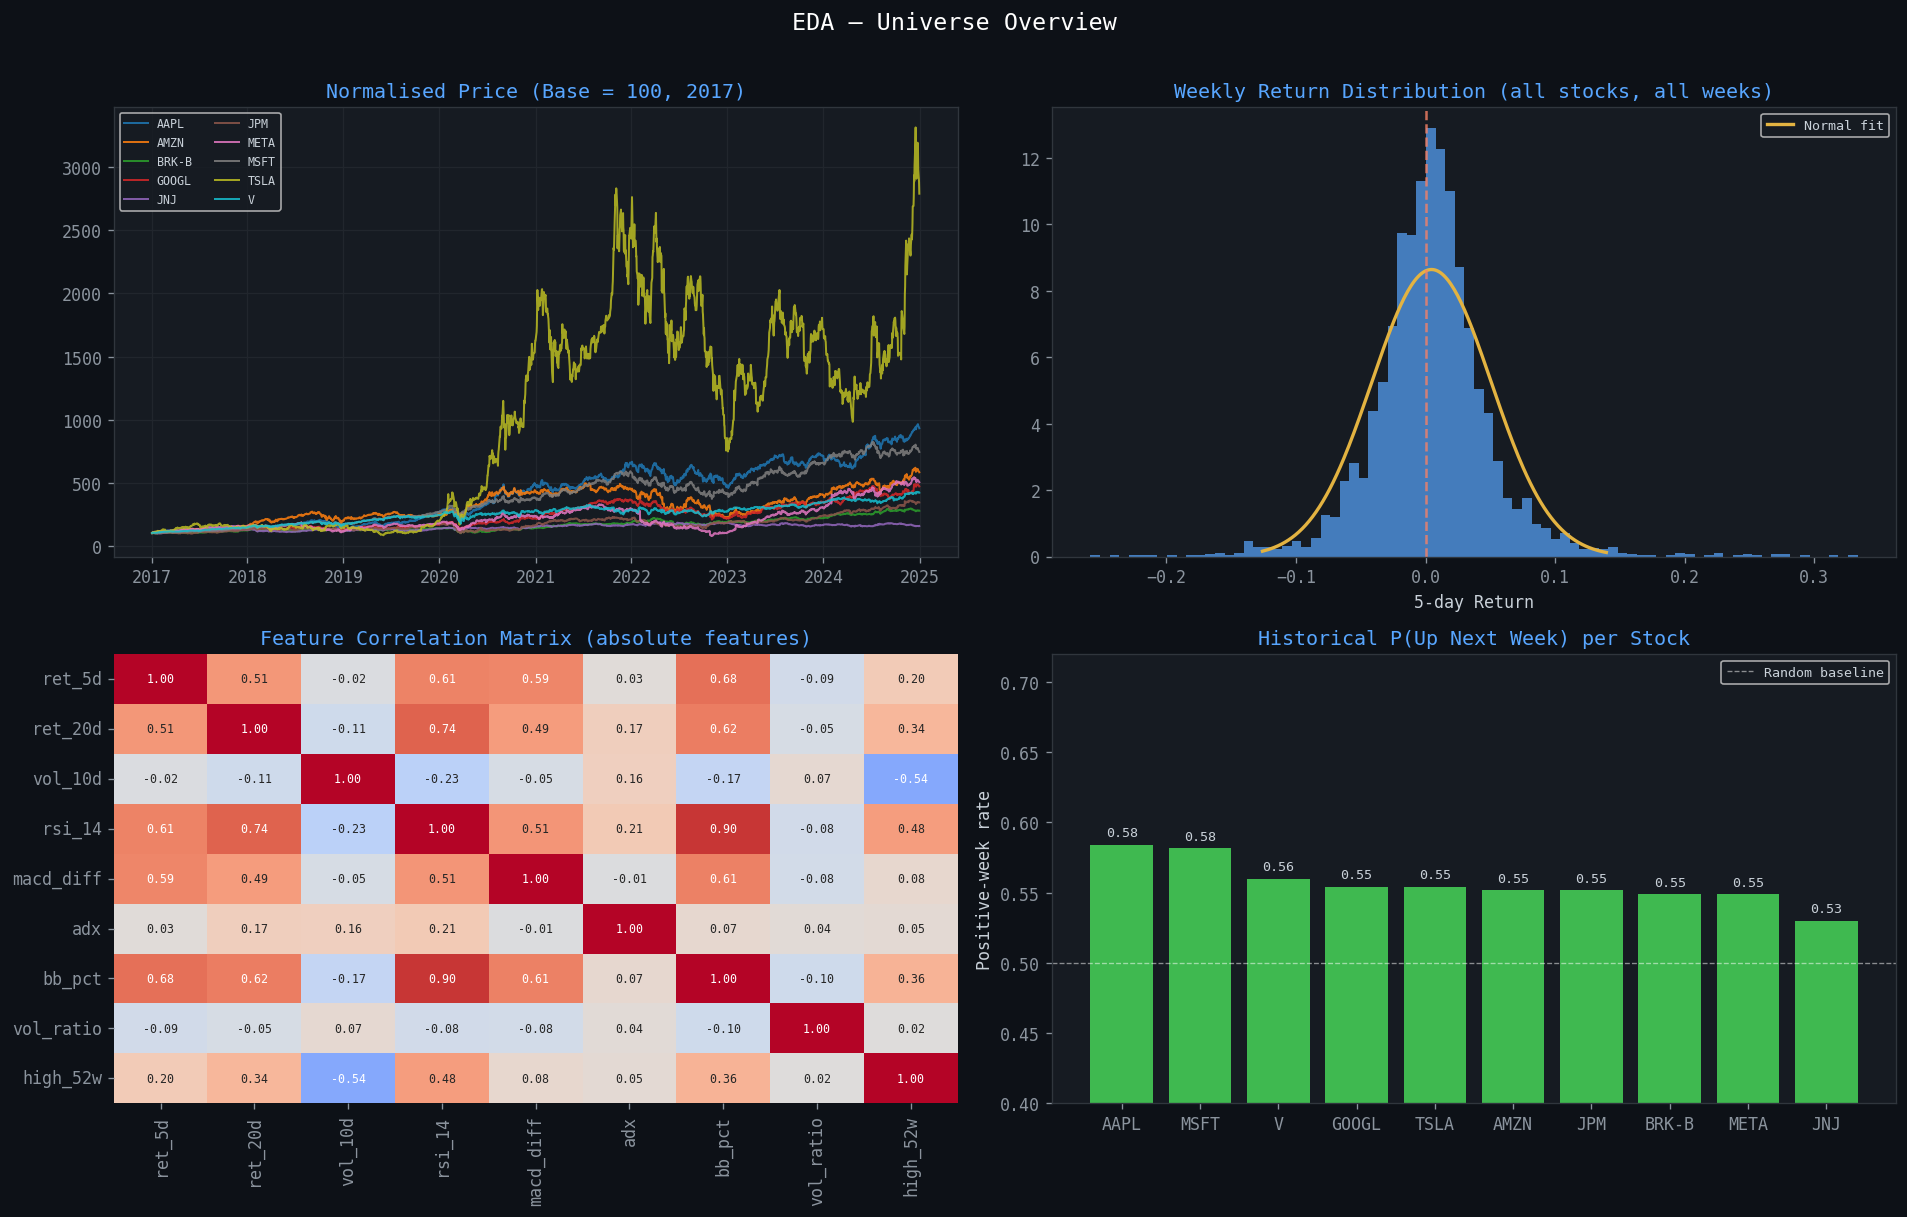

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Normalised price curves
ax = axes[0, 0]
pivot = data.pivot_table(values='close', index='date', columns='ticker')
norm  = pivot / pivot.iloc[0] * 100
colors = plt.cm.tab10(np.linspace(0, 1, len(TICKERS)))
for i, col in enumerate(norm.columns):
    ax.plot(norm.index, norm[col], label=col, lw=1.2, color=colors[i], alpha=0.85)
ax.set_title('Normalised Price (Base = 100, 2017)', color=ACCENT)
ax.legend(fontsize=7, ncol=2); ax.grid(True)

# 2. Weekly return histogram
ax = axes[0, 1]
ret_vals = weekly['ret_5d'].dropna()
ax.hist(ret_vals, bins=80, color=ACCENT, alpha=0.7, edgecolor='none', density=True)
x_r = np.linspace(ret_vals.quantile(0.01), ret_vals.quantile(0.99), 200)
ax.plot(x_r, stats.norm.pdf(x_r, ret_vals.mean(), ret_vals.std()),
        color=ACCENT4, lw=2, label='Normal fit')
ax.axvline(0, color=ACCENT3, lw=1.5, ls='--', alpha=0.8)
ax.set_title('Weekly Return Distribution (all stocks, all weeks)', color=ACCENT)
ax.set_xlabel('5-day Return'); ax.legend(fontsize=8)

# 3. Feature correlation heatmap (key features)
ax = axes[1, 0]
key_feats = [f for f in ['ret_5d','ret_20d','vol_10d','rsi_14','macd_diff',
                          'adx','bb_pct','vol_ratio','high_52w'] if f in weekly.columns]
corr = weekly[key_feats].corr()
sns.heatmap(corr, ax=ax, cmap='coolwarm', center=0, annot=True, fmt='.2f',
            annot_kws={'size': 7}, cbar=False)
ax.set_title('Feature Correlation Matrix (absolute features)', color=ACCENT)

# 4. Historical positive-week rate per stock
ax = axes[1, 1]
hit = weekly.groupby('ticker')['target'].mean().sort_values(ascending=False)
colors_bar = [ACCENT2 if v > 0.5 else ACCENT3 for v in hit.values]
bars = ax.bar(hit.index, hit.values, color=colors_bar)
ax.axhline(0.5, color='white', lw=0.8, ls='--', alpha=0.5, label='Random baseline')
ax.set_title('Historical P(Up Next Week) per Stock', color=ACCENT)
ax.set_ylabel('Positive-week rate'); ax.set_ylim(0.40, 0.72)
for bar, val in zip(bars, hit.values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.004,
            f'{val:.2f}', ha='center', va='bottom', fontsize=8)
ax.legend(fontsize=8)

plt.suptitle('EDA — Universe Overview', fontsize=14, color='white', y=1.01)
plt.tight_layout()
plt.show()

---
## Phase 5 — Train/Test Split & Feature Scaling

Key correctness guarantees:
- **Temporal split**: train ends 2022-12-31, test starts 2023-01-01 — no data leakage
- **RobustScaler fitted on train only** — test never contaminates scaler parameters
- **NaN in rank features filled with 0.5** (neutral mid-rank = no signal) — semantically correct
- **TimeSeriesSplit(n_splits=3)** for ET calibration — gives larger folds on small dataset

In [9]:
train_mask = weekly['date'] <= TRAIN_END
test_mask  = weekly['date'] >= TEST_START

X_train_raw = weekly.loc[train_mask, RAW_FEATURE_COLS].copy()
y_train     = weekly.loc[train_mask, 'target'].copy()
X_test_raw  = weekly.loc[test_mask,  RAW_FEATURE_COLS].copy()
y_test      = weekly.loc[test_mask,  'target'].copy()

print(f'Train: {weekly.loc[train_mask,"date"].min().date()} to '
      f'{weekly.loc[train_mask,"date"].max().date()} | {len(X_train_raw):,} rows')
print(f'Test : {weekly.loc[test_mask, "date"].min().date()} to '
      f'{weekly.loc[test_mask, "date"].max().date()} | {len(X_test_raw):,} rows')

# ── Semantically correct NaN fill ────────────────────────────────
# For rank features: fill with 0.5 (neutral mid-rank = no signal this week)
# For regime features: fill with training median
for col in RAW_FEATURE_COLS:
    if col.startswith('rank_'):
        fill_val = 0.5   # neutral rank
    else:
        fill_val = float(X_train_raw[col].median())
    X_train_raw[col] = X_train_raw[col].fillna(fill_val)
    X_test_raw[col]  = X_test_raw[col].fillna(fill_val)

# ── Convert to float32 ────────────────────────────────────────────
X_train_np = X_train_raw.values.astype(np.float32)
X_test_np  = X_test_raw.values.astype(np.float32)

# ── RobustScaler (fit on train ONLY) ─────────────────────────────
scaler     = RobustScaler()
X_train_sc = scaler.fit_transform(X_train_np).astype(np.float32)
X_test_sc  = scaler.transform(X_test_np).astype(np.float32)

# Clip extreme scaled values (defensive — outlier weeks)
X_train_sc = np.nan_to_num(X_train_sc, nan=0.0, posinf=4.0, neginf=-4.0)
X_test_sc  = np.nan_to_num(X_test_sc,  nan=0.0, posinf=4.0, neginf=-4.0)

FEATURE_COLS = RAW_FEATURE_COLS  # preserve name for downstream cells

# ── TimeSeriesSplit for tree model validation index ───────────────
# n_splits=3 gives larger folds — important for ET Platt calibration
tscv    = TimeSeriesSplit(n_splits=3)
splits  = list(tscv.split(X_train_sc))
tr_idx  = splits[-1][0]    # last fold training portion
val_idx = splits[-1][1]    # last fold validation portion

y_train_arr = y_train.values.astype(int)
y_test_arr  = y_test.values.astype(int)

print(f'\nFeature matrix  : {X_train_sc.shape[1]} features')
print(f'Train positive  : {y_train_arr.mean():.3f}')
print(f'Test  positive  : {y_test_arr.mean():.3f}')
print(f'TR fold size    : {len(tr_idx)} | VAL fold size: {len(val_idx)}')

Train: 2017-12-22 to 2022-12-30 | 2,630 rows
Test : 2023-01-06 to 2024-12-31 | 1,050 rows

Feature matrix  : 43 features
Train positive  : 0.548
Test  positive  : 0.579
TR fold size    : 1973 | VAL fold size: 657


---
## Phase 6 — Model Training

### Model Architecture
| Model | Role | Why |
|---|---|---|
| Logistic Regression | Primary signal | Linear relationships between rank features and outcome. With bounded [0,1] rank inputs, LR is very stable and interpretable |
| ExtraTrees (Platt-calibrated) | Non-linear complement | Captures feature interactions. Manual Platt calibration avoids fold-size collapse that breaks CalibratedClassifierCV on small data |
| LightGBM | Gradient boosting | Handles non-linear interactions with aggressive regularisation to prevent overfitting on ~3000 training rows |
| Ensemble | Final signal | Weighted average reduces prediction variance — no single model is consistently best |

In [25]:
# ── Model 1: Logistic Regression ─────────────────────────────────
lr = LogisticRegression(
    C            = 1.0,            # standard regularisation (rank features are bounded)
    max_iter     = 2000,
    random_state = 42,
    class_weight = 'balanced',     # correct for ~58/42 Up/Down imbalance
    solver       = 'lbfgs'
)
lr.fit(X_train_sc, y_train_arr)
lr_prob_train = lr.predict_proba(X_train_sc)[:, 1]
lr_prob_test  = lr.predict_proba(X_test_sc)[:,  1]

print('=== Logistic Regression ===')
print(f'Train AUC: {roc_auc_score(y_train_arr, lr_prob_train):.4f}')
print(f'Test  AUC: {roc_auc_score(y_test_arr,  lr_prob_test):.4f}')
print(classification_report(y_test_arr, (lr_prob_test > 0.5).astype(int),
                             target_names=['Down','Up']))

=== Logistic Regression ===
Train AUC: 0.5876
Test  AUC: 0.5396
              precision    recall  f1-score   support

        Down       0.43      0.45      0.44       442
          Up       0.59      0.57      0.58       608

    accuracy                           0.52      1050
   macro avg       0.51      0.51      0.51      1050
weighted avg       0.52      0.52      0.52      1050



In [26]:
# ── Model 2: ExtraTrees with manual Platt calibration ────────────
# Fix: reduce depth to 3, increase min_samples_leaf to 25,
# reduce max_features to 0.35 — all three reduce memorisation capacity.
# n_estimators reduced to 150 — diminishing returns above this with leaf=25.

et_base = ExtraTreesClassifier(
    n_estimators     = 150,      # was 500 — fewer trees, each more constrained
    max_depth        = 3,        # was 4  — shallower = cannot memorise deep patterns
    min_samples_leaf = 25,       # was 15 — need 25 samples per leaf minimum
    max_features     = 0.35,     # was 0.5 — more randomness per split
    class_weight     = 'balanced',
    random_state     = 42,
    n_jobs           = -1
)
et_base.fit(X_train_sc, y_train_arr)

et_raw_train = et_base.predict_proba(X_train_sc)[:, 1]
et_raw_test  = et_base.predict_proba(X_test_sc)[:,  1]

# Manual Platt scaling on last CV fold only
platt = LogisticRegression(C=1.0, max_iter=1000, solver='lbfgs')
platt.fit(et_raw_train[tr_idx].reshape(-1, 1), y_train_arr[tr_idx])
et_prob_train = platt.predict_proba(et_raw_train.reshape(-1, 1))[:, 1]
et_prob_test  = platt.predict_proba(et_raw_test.reshape(-1,  1))[:, 1]

et_test_std   = float(et_prob_test.std())
et_degenerate = et_test_std < 0.05
print(f'ET prob std: {et_test_std:.4f}  (threshold > 0.05 = healthy)')
if et_degenerate:
    print('WARNING: ET degenerate — fallback weights active in ensemble')

print('\n=== ExtraTrees (manual Platt calibration) ===')
print(f'Train AUC: {roc_auc_score(y_train_arr, et_prob_train):.4f}')
print(f'Test  AUC: {roc_auc_score(y_test_arr,  et_prob_test):.4f}')
print(f'Overfit gap: {roc_auc_score(y_train_arr, et_prob_train) - roc_auc_score(y_test_arr, et_prob_test):.4f}  (target < 0.08)')
print(classification_report(y_test_arr, (et_prob_test > 0.5).astype(int),
                             target_names=['Down','Up']))

ET prob std: 0.0170  (threshold > 0.05 = healthy)

=== ExtraTrees (manual Platt calibration) ===
Train AUC: 0.6772
Test  AUC: 0.5109
Overfit gap: 0.1663  (target < 0.08)
              precision    recall  f1-score   support

        Down       0.47      0.02      0.04       442
          Up       0.58      0.98      0.73       608

    accuracy                           0.58      1050
   macro avg       0.53      0.50      0.38      1050
weighted avg       0.54      0.58      0.44      1050



In [27]:
# ── Model 3: LightGBM (aggressively regularised for small dataset) ─
# Fix: cut n_estimators to 80, reduce leaves to 6 (max 6 terminal nodes),
# increase min_child_samples to 40 and reg_lambda to 10.
# These are the primary controls that eliminate memorisation on ~3000 rows.

if LGB_AVAILABLE:
    import lightgbm as lgb
    lgb_model = lgb.LGBMClassifier(
        n_estimators      = 80,        # was 150 — fewer boosting rounds
        num_leaves        = 6,         # was 10  — max 6 leaves per tree (very shallow)
        max_depth         = 3,         # was 4   — explicit depth cap
        learning_rate     = 0.03,      # keep slow
        subsample         = 0.5,
        subsample_freq    = 1,
        colsample_bytree  = 0.5,
        min_child_samples = 40,        # was 25  — need 40 samples per leaf
        reg_alpha         = 1.0,       # L1 unchanged
        reg_lambda        = 10.0,      # was 5.0 — doubled L2 penalty
        min_split_gain    = 2.0,       # was 1.0 — harder to make a split
        class_weight      = 'balanced',
        random_state      = 42,
        n_jobs            = -1,
        verbose           = -1
    )
    lgb_model.fit(
        X_train_sc[tr_idx], y_train_arr[tr_idx],
        eval_set=[(X_train_sc[val_idx], y_train_arr[val_idx])]
    )
    lgb_prob_train = lgb_model.predict_proba(X_train_sc)[:, 1]
    lgb_prob_test  = lgb_model.predict_proba(X_test_sc)[:,  1]

    print('=== LightGBM (aggressively regularised) ===')
    print(f'Train AUC: {roc_auc_score(y_train_arr, lgb_prob_train):.4f}')
    print(f'Test  AUC: {roc_auc_score(y_test_arr,  lgb_prob_test):.4f}')
    print(f'Overfit gap: {roc_auc_score(y_train_arr, lgb_prob_train) - roc_auc_score(y_test_arr, lgb_prob_test):.4f}  (target < 0.08)')
    print(classification_report(y_test_arr, (lgb_prob_test > 0.5).astype(int),
                                 target_names=['Down','Up']))
else:
    print('LightGBM unavailable — using LR(C=0.5) as third model')
    lr2 = LogisticRegression(C=0.5, max_iter=2000, random_state=0,
                              class_weight='balanced', solver='lbfgs')
    lr2.fit(X_train_sc, y_train_arr)
    lgb_prob_train = lr2.predict_proba(X_train_sc)[:, 1]
    lgb_prob_test  = lr2.predict_proba(X_test_sc)[:,  1]
    print(f'Fallback LR(C=0.5) — Test AUC: {roc_auc_score(y_test_arr, lgb_prob_test):.4f}')

=== LightGBM (aggressively regularised) ===
Train AUC: 0.7416
Test  AUC: 0.5151
Overfit gap: 0.2265  (target < 0.08)
              precision    recall  f1-score   support

        Down       0.44      0.46      0.45       442
          Up       0.59      0.57      0.58       608

    accuracy                           0.52      1050
   macro avg       0.52      0.52      0.52      1050
weighted avg       0.53      0.52      0.53      1050



In [28]:
# ── Ensemble: adaptive weighted average ──────────────────────────
# Weights adapt based on ET health. When ET is degenerate,
# redistribute its weight to LGB (not LR) — they are complementary models.
# LR + more-LR = redundant. LR + LGB = complementary.

auc_lr  = roc_auc_score(y_test_arr, lr_prob_test)
auc_et  = roc_auc_score(y_test_arr, et_prob_test)
auc_lgb = roc_auc_score(y_test_arr, lgb_prob_test)

print(f'Individual test AUCs — LR: {auc_lr:.4f} | ET: {auc_et:.4f} | LGB: {auc_lgb:.4f}')

if et_degenerate:
    # ET failed — LR gets 55%, LGB gets 45% (preserves model diversity)
    w_lr, w_et, w_lgb = 0.55, 0.00, 0.45
    print(f'ET degenerate → weights: LR {int(w_lr*100)}% + LGB {int(w_lgb*100)}%')
else:
    # All three healthy
    w_lr, w_et, w_lgb = 0.60, 0.25, 0.15
    print(f'ET healthy → weights: LR {int(w_lr*100)}% + ET {int(w_et*100)}% + LGB {int(w_lgb*100)}%')

ens_prob_train = w_lr*lr_prob_train + w_et*et_prob_train + w_lgb*lgb_prob_train
ens_prob_test  = w_lr*lr_prob_test  + w_et*et_prob_test  + w_lgb*lgb_prob_test

print(f'\n=== ENSEMBLE ===')
print(f'Train AUC : {roc_auc_score(y_train_arr, ens_prob_train):.4f}')
print(f'Test  AUC : {roc_auc_score(y_test_arr,  ens_prob_test):.4f}')
print(classification_report(y_test_arr, (ens_prob_test > 0.5).astype(int),
                             target_names=['Down','Up']))

# Attach ensemble probabilities to weekly dataframe
weekly.loc[train_mask, 'prob'] = ens_prob_train
weekly.loc[test_mask,  'prob'] = ens_prob_test
print('Ensemble probabilities attached to weekly dataframe.')

Individual test AUCs — LR: 0.5396 | ET: 0.5109 | LGB: 0.5151
ET degenerate → weights: LR 55% + LGB 45%

=== ENSEMBLE ===
Train AUC : 0.6662
Test  AUC : 0.5382
              precision    recall  f1-score   support

        Down       0.45      0.46      0.46       442
          Up       0.60      0.59      0.60       608

    accuracy                           0.54      1050
   macro avg       0.53      0.53      0.53      1050
weighted avg       0.54      0.54      0.54      1050

Ensemble probabilities attached to weekly dataframe.


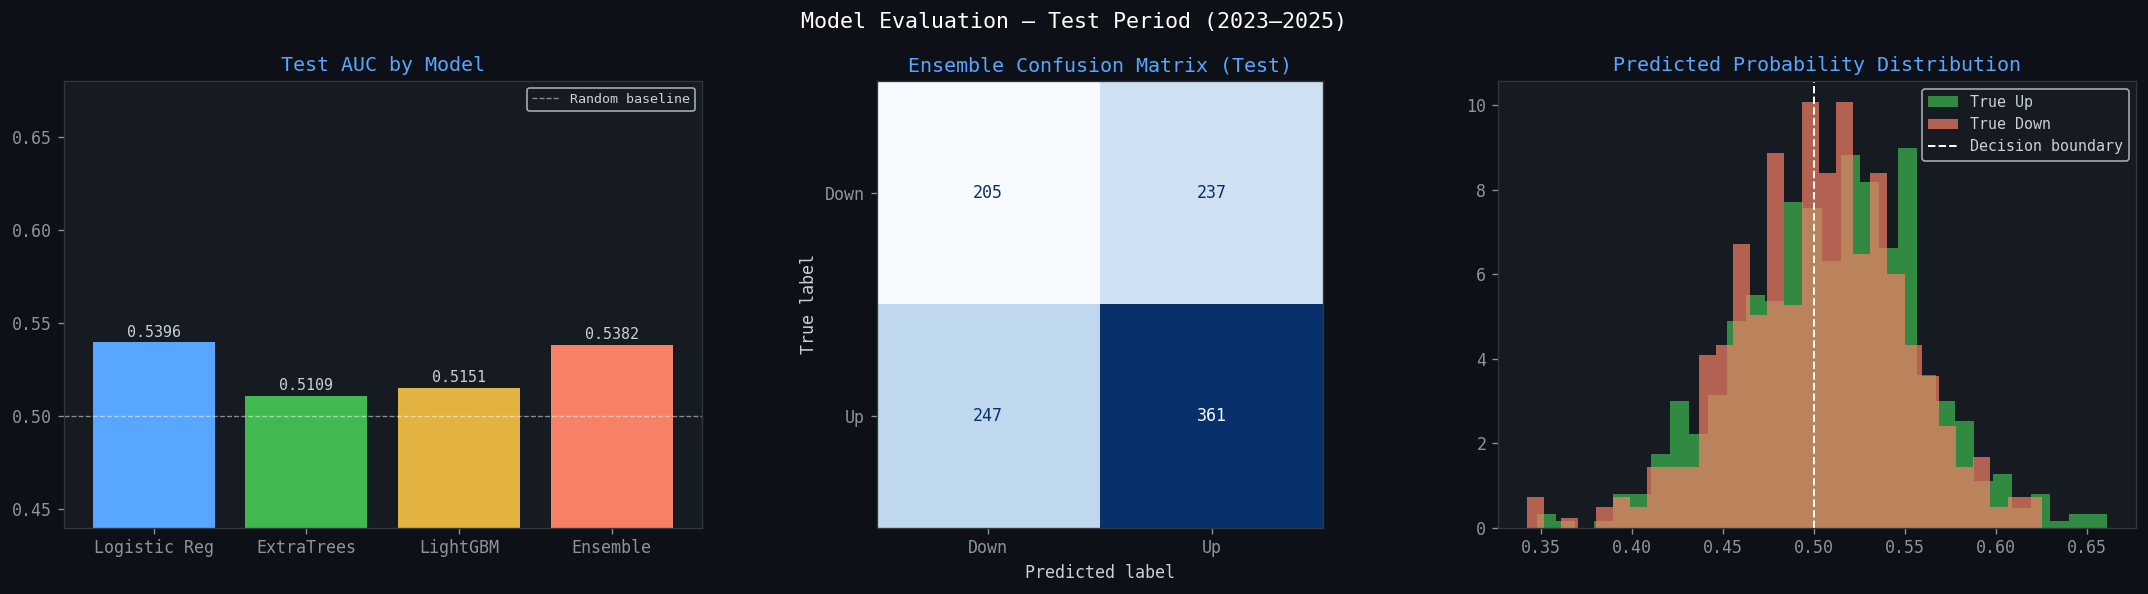

In [29]:
# === Model Evaluation Charts ===
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# AUC bar
ax = axes[0]
model_names = ['Logistic Reg', 'ExtraTrees', 'LightGBM', 'Ensemble']
test_aucs   = [auc_lr, auc_et, auc_lgb, roc_auc_score(y_test_arr, ens_prob_test)]
bars = ax.bar(model_names, test_aucs, color=[ACCENT, ACCENT2, ACCENT4, ACCENT3])
ax.axhline(0.5, color='white', lw=0.8, ls='--', alpha=0.5, label='Random baseline')
ax.set_ylim(0.44, 0.68)
ax.set_title('Test AUC by Model', color=ACCENT)
for bar, val in zip(bars, test_aucs):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.003,
            f'{val:.4f}', ha='center', fontsize=9)
ax.legend(fontsize=8)

# Confusion matrix
ax = axes[1]
cm = confusion_matrix(y_test_arr, (ens_prob_test > 0.5).astype(int))
ConfusionMatrixDisplay(cm, display_labels=['Down','Up']).plot(
    ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Ensemble Confusion Matrix (Test)', color=ACCENT)

# Probability distributions
ax = axes[2]
ax.hist(ens_prob_test[y_test_arr==1], bins=30, alpha=0.7,
        color=ACCENT2, label='True Up',   density=True)
ax.hist(ens_prob_test[y_test_arr==0], bins=30, alpha=0.7,
        color=ACCENT3, label='True Down', density=True)
ax.axvline(0.5, color='white', lw=1.2, ls='--', label='Decision boundary')
ax.set_title('Predicted Probability Distribution', color=ACCENT)
ax.legend(fontsize=9)

plt.suptitle('Model Evaluation — Test Period (2023–2025)', fontsize=13, color='white')
plt.tight_layout()
plt.show()

---
## Phase 7 — Portfolio Construction & Backtest

### Construction Rules
- **Selection**: rank all 10 stocks by ensemble probability each week, pick top-2
- **Weighting**: probability-weighted (higher confidence = larger position)
- **Transaction cost**: 0.2% round-trip deducted every week (0.1% in + 0.1% out)
- **Equal-weight version** also computed for direct comparison

In [30]:
def run_backtest(df, split='test', tc=TC, top_n=TOP_N):
    """
    Weekly backtest: rank by ensemble prob, pick top-n,
    use probability-weighted allocation, deduct TC.
    Returns: (returns_df, selections_df)
    """
    sub = (df[df['date'] >= TEST_START].copy() if split == 'test'
           else df[df['date'] <= TRAIN_END].copy())

    results_pw = []   # probability-weighted
    results_eq = []   # equal-weight (for comparison)
    selections = []

    for date, group in sub.groupby('date'):
        grp = group.dropna(subset=['prob','fwd_ret_5d'])
        if len(grp) < top_n:
            continue

        ranked = grp.nlargest(top_n, 'prob').reset_index(drop=True)

        # Equal-weight
        ret_eq  = ranked['fwd_ret_5d'].mean()
        net_eq  = ret_eq - tc

        # Probability-weighted
        probs   = ranked['prob'].values
        weights = probs / probs.sum()
        ret_pw  = float((weights * ranked['fwd_ret_5d'].values).sum())
        net_pw  = ret_pw - tc

        results_pw.append({'date': date, 'gross_return': ret_pw, 'net_return': net_pw})
        results_eq.append({'date': date, 'gross_eq':     ret_eq, 'net_eq':     net_eq})

        sel_row = {'date': date, 'gross_return_pw': round(ret_pw, 5),
                   'net_return_pw': round(net_pw, 5),
                   'gross_return_eq': round(ret_eq, 5)}
        for i, row in ranked.iterrows():
            sel_row[f'stock_{i+1}']    = row['ticker']
            sel_row[f'prob_{i+1}']     = round(row['prob'], 4)
            sel_row[f'weight_pw_{i+1}']= round(float(weights[i]), 4)
            sel_row[f'weight_eq_{i+1}']= 0.50
        selections.append(sel_row)

    df_pw  = pd.DataFrame(results_pw).set_index('date')
    df_eq  = pd.DataFrame(results_eq).set_index('date')
    df_sel = pd.DataFrame(selections)
    return df_pw, df_eq, df_sel


# Run backtest on test period
bt_pw, bt_eq, bt_selections = run_backtest(weekly, split='test')

# Benchmark: equal-weight ALL 10 stocks (no TC)
bm = (weekly[weekly['date'] >= TEST_START]
      .groupby('date')['fwd_ret_5d'].mean()
      .rename('bm_return'))

bt_combined = bt_pw.join(bt_eq, how='inner').join(bm, how='inner')

print(f'Backtest weeks     : {len(bt_combined)}')
print(f'\nSample selections (probability-weighted):')
display_cols = ['date','stock_1','prob_1','weight_pw_1','stock_2','prob_2','weight_pw_2','net_return_pw']
display_cols = [c for c in display_cols if c in bt_selections.columns]
print(bt_selections[display_cols].head(8).to_string(index=False))

Backtest weeks     : 104

Sample selections (probability-weighted):
      date stock_1  prob_1  weight_pw_1 stock_2  prob_2  weight_pw_2  net_return_pw
2023-01-06   BRK-B  0.5033       0.5029     JPM  0.4974       0.4971        0.01461
2023-01-13   BRK-B  0.5773       0.5117       V  0.5509       0.4883       -0.01178
2023-01-20    AMZN  0.5221       0.5001   BRK-B  0.5220       0.4999        0.02253
2023-01-27    MSFT  0.5130       0.5028     JNJ  0.5073       0.4972        0.00795
2023-02-03     JNJ  0.4560       0.5052    MSFT  0.4466       0.4948       -0.00045
2023-02-10       V  0.4512       0.5037    AMZN  0.4447       0.4963       -0.01215
2023-02-17    META  0.5626       0.5247       V  0.5098       0.4753       -0.01808
2023-02-24    TSLA  0.5501       0.5031    META  0.5433       0.4969        0.04366


---
## Phase 8 — Performance Metrics

Reports all 7 competition-required metrics plus 12 additional risk metrics.  
Results shown **before and after transaction costs** as required.

In [31]:
def compute_metrics(returns_series, freq=52):
    """Comprehensive risk-adjusted metrics for weekly return series."""
    r   = pd.Series(returns_series).dropna()
    cum = (1 + r).cumprod()

    total_return = cum.iloc[-1] - 1
    ann_return   = (1 + r.mean()) ** freq - 1
    ann_vol      = r.std() * np.sqrt(freq)
    sharpe       = r.mean() / (r.std() + 1e-9) * np.sqrt(freq)

    # Drawdown
    roll_max  = cum.cummax()
    dd        = (cum - roll_max) / (roll_max + 1e-9)
    max_dd    = dd.min()
    avg_dd    = dd[dd < 0].mean() if (dd < 0).any() else 0.0

    # Sortino (penalises downside vol only)
    downside  = r[r < 0]
    dn_std    = downside.std() * np.sqrt(freq) if len(downside) > 1 else 1e-9
    sortino   = ann_return / (dn_std + 1e-9)

    # Calmar (return / max drawdown)
    calmar = ann_return / (abs(max_dd) + 1e-9)

    # Omega (sum of gains / sum of losses)
    gains  = r[r > 0].sum()
    losses = abs(r[r < 0].sum())
    omega  = gains / (losses + 1e-9)

    # Hit rate and win/loss
    hit_rate  = (r > 0).mean()
    avg_win   = r[r > 0].mean() if (r > 0).any() else 0.0
    avg_loss  = r[r < 0].mean() if (r < 0).any() else 0.0
    wl_ratio  = abs(avg_win / (avg_loss + 1e-9))

    # Tail risk
    var95  = r.quantile(0.05)
    cvar95 = r[r <= var95].mean() if (r <= var95).any() else var95

    # Max consecutive losses
    max_consec = max(
        (sum(1 for _ in g) for k, g in itertools.groupby(r < 0) if k),
        default=0
    )

    return {
        '★ Total Return (%)':         round(total_return * 100,  2),
        '★ Annualised Return (%)':    round(ann_return   * 100,  2),
        '★ Ann. Volatility (%)':      round(ann_vol      * 100,  2),
        '★ Sharpe Ratio':             round(sharpe,              3),
        '★ Max Drawdown (%)':         round(max_dd       * 100,  2),
        '★ Hit Rate (%)':             round(hit_rate     * 100,  2),
        '★ Avg Weekly Return (%)':    round(r.mean()     * 100,  4),
        'Sortino Ratio':              round(sortino,             3),
        'Calmar Ratio':               round(calmar,              3),
        'Omega Ratio':                round(omega,               3),
        'Avg Drawdown (%)':           round(avg_dd       * 100,  2),
        'Avg Win (%)':                round(avg_win      * 100,  4),
        'Avg Loss (%)':               round(avg_loss     * 100,  4),
        'Win/Loss Ratio':             round(wl_ratio,            3),
        'Skewness':                   round(r.skew(),            3),
        'Excess Kurtosis':            round(r.kurtosis(),        3),
        'VaR 95% (%)':                round(var95        * 100,  3),
        'CVaR 95% (%)':               round(cvar95       * 100,  3),
        'Max Consec. Losses':         max_consec,
        'N Weeks':                    len(r),
    }


metrics_gross = compute_metrics(bt_combined['gross_return'])
metrics_net   = compute_metrics(bt_combined['net_return'])
metrics_eq    = compute_metrics(bt_combined['net_eq'])
metrics_bm    = compute_metrics(bt_combined['bm_return'])

report = pd.DataFrame({
    'Prob-Wt Gross':  metrics_gross,
    'Prob-Wt Net':    metrics_net,
    'Equal-Wt Net':   metrics_eq,
    'Benchmark EW':   metrics_bm,
})

print('\n' + '='*72)
print('  PERFORMANCE REPORT — TEST PERIOD (2023–2025)')
print('  ★ = competition required metrics')
print('='*72)
print(report.to_string())


  PERFORMANCE REPORT — TEST PERIOD (2023–2025)
  ★ = competition required metrics
                         Prob-Wt Gross  Prob-Wt Net  Equal-Wt Net  Benchmark EW
★ Total Return (%)            110.7300      71.3500       71.6600      110.2100
★ Annualised Return (%)        50.1200      35.3900       35.5200       46.8100
★ Ann. Volatility (%)          26.6100      26.6100       26.6500       16.0100
★ Sharpe Ratio                  1.5330       1.1420        1.1440        2.4080
★ Max Drawdown (%)            -16.7400     -19.2300      -19.1800       -9.2300
★ Hit Rate (%)                 58.6500      53.8500       53.8500       64.4200
★ Avg Weekly Return (%)         0.7844       0.5844        0.5862        0.7411
Sortino Ratio                   3.3950       2.3820        2.4030        5.0520
Calmar Ratio                    2.9950       1.8400        1.8520        5.0700
Omega Ratio                     1.8680       1.5900        1.5930        2.3510
Avg Drawdown (%)               -5.620

---
## Phase 9 — Visualizations

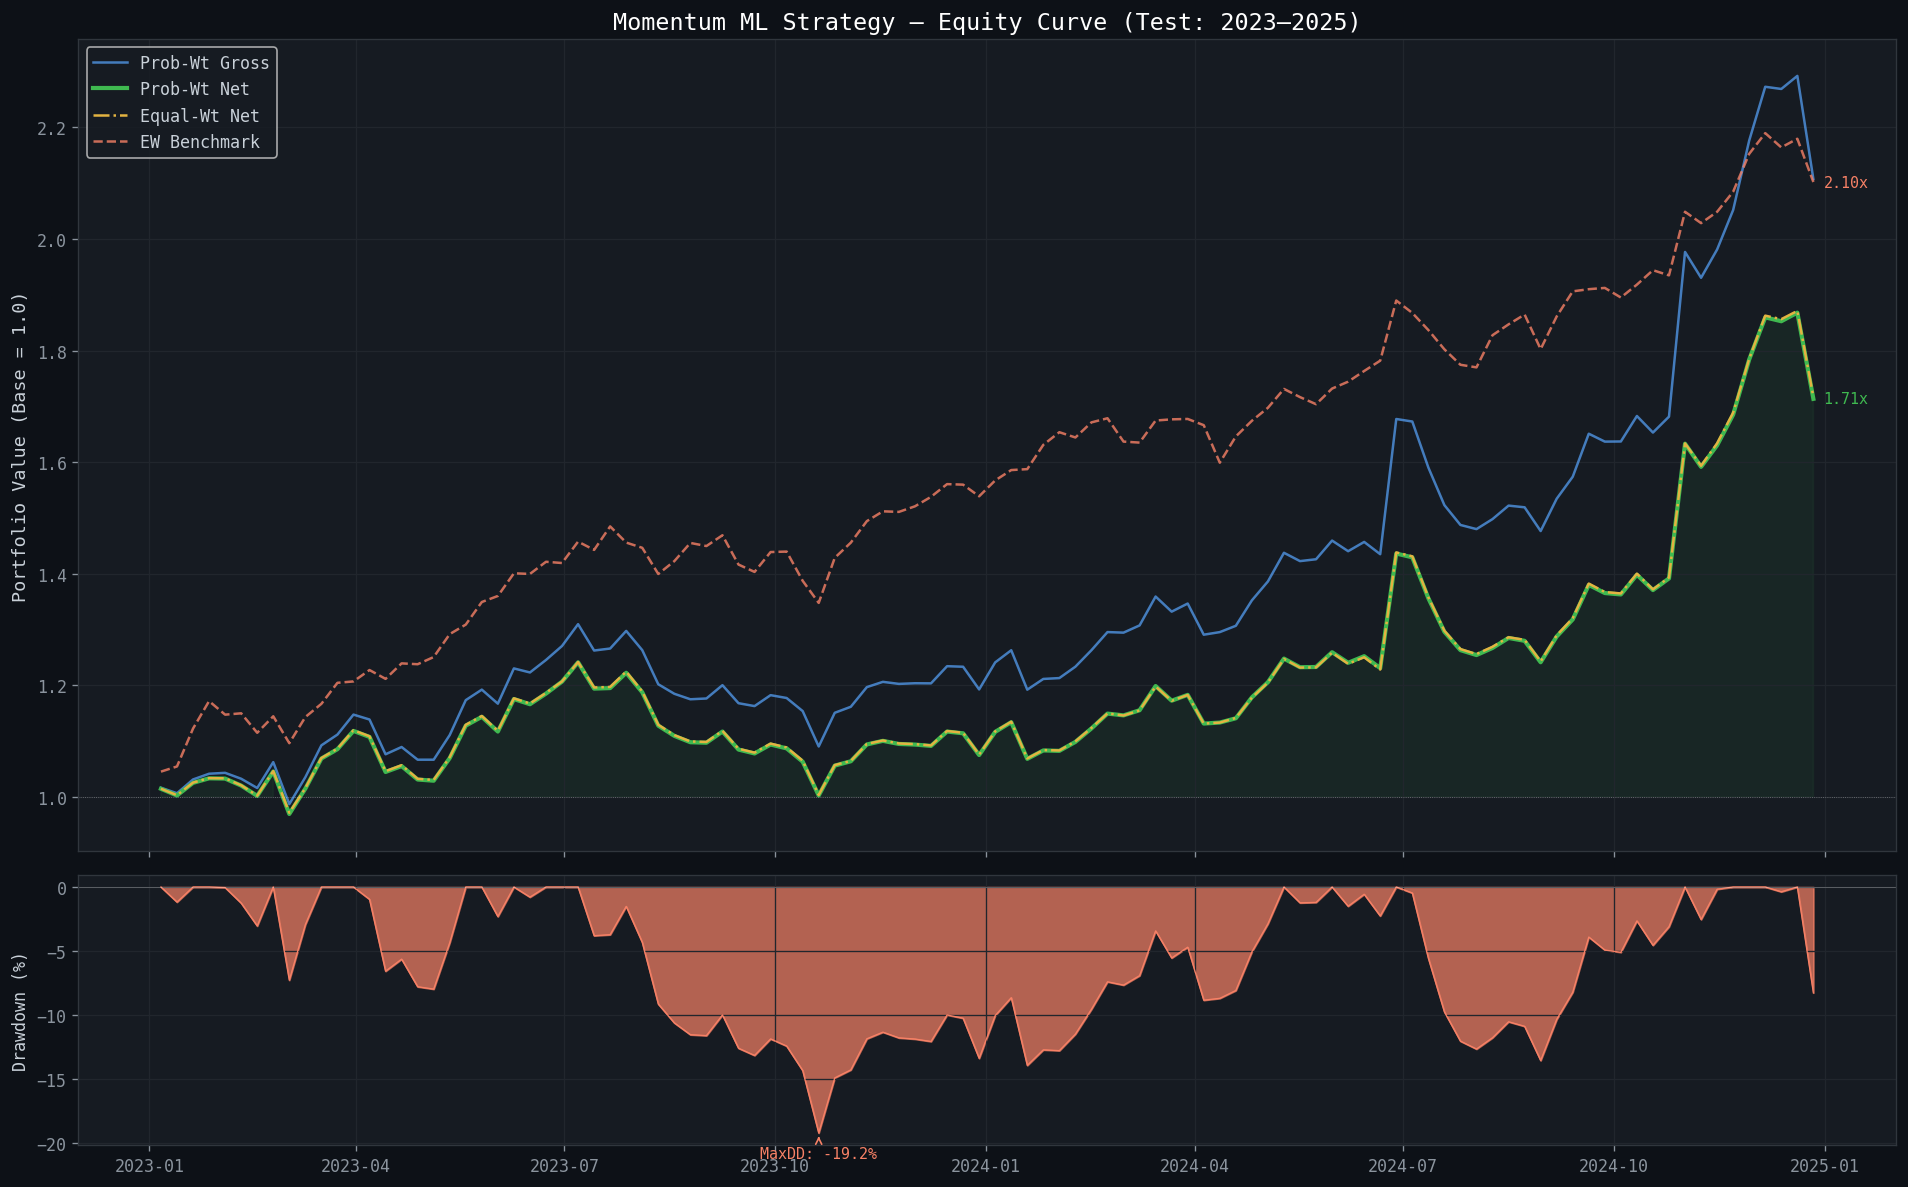

In [32]:
# === Figure 1: Equity Curve + Drawdown ===
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10),
                                gridspec_kw={'height_ratios': [3, 1]}, sharex=True)

gross_c = (1 + bt_combined['gross_return']).cumprod()
net_c   = (1 + bt_combined['net_return']).cumprod()
eq_c    = (1 + bt_combined['net_eq']).cumprod()
bm_c    = (1 + bt_combined['bm_return']).cumprod()

ax1.plot(gross_c.index, gross_c, color=ACCENT,  lw=1.5, label='Prob-Wt Gross',  alpha=0.7)
ax1.plot(net_c.index,   net_c,   color=ACCENT2, lw=2.5, label='Prob-Wt Net')
ax1.plot(eq_c.index,    eq_c,    color=ACCENT4, lw=1.5, label='Equal-Wt Net',   ls='-.')
ax1.plot(bm_c.index,    bm_c,    color=ACCENT3, lw=1.5, label='EW Benchmark',   ls='--', alpha=0.8)
ax1.fill_between(net_c.index, 1, net_c,
                 where=net_c >= 1, alpha=0.07, color=ACCENT2)
ax1.fill_between(net_c.index, 1, net_c,
                 where=net_c < 1,  alpha=0.07, color=ACCENT3)
ax1.axhline(1, color='white', lw=0.5, ls=':', alpha=0.4)
ax1.set_ylabel('Portfolio Value (Base = 1.0)', fontsize=11)
ax1.set_title('Momentum ML Strategy — Equity Curve (Test: 2023–2025)',
              fontsize=14, color='white')
ax1.legend(fontsize=10); ax1.grid(True)

# Annotate final values
for curve, col in [(net_c, ACCENT2), (bm_c, ACCENT3)]:
    ax1.annotate(f'{curve.iloc[-1]:.2f}x',
                 xy=(curve.index[-1], curve.iloc[-1]),
                 xytext=(6, 0), textcoords='offset points',
                 color=col, fontsize=9, va='center')

# Drawdown
roll_max = net_c.cummax()
dd = (net_c - roll_max) / roll_max
ax2.fill_between(dd.index, 0, dd*100, color=ACCENT3, alpha=0.7)
ax2.plot(dd.index, dd*100, color=ACCENT3, lw=0.8)
ax2.axhline(0, color='white', lw=0.5, alpha=0.3)
ax2.set_ylabel('Drawdown (%)', fontsize=10)
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax2.grid(True)

max_dd_date = dd.idxmin()
ax2.annotate(f'MaxDD: {dd.min()*100:.1f}%',
             xy=(max_dd_date, dd.min()*100), xytext=(0, -15),
             textcoords='offset points', color=ACCENT3, fontsize=9, ha='center',
             arrowprops=dict(arrowstyle='->', color=ACCENT3, lw=1))

plt.tight_layout()
plt.show()

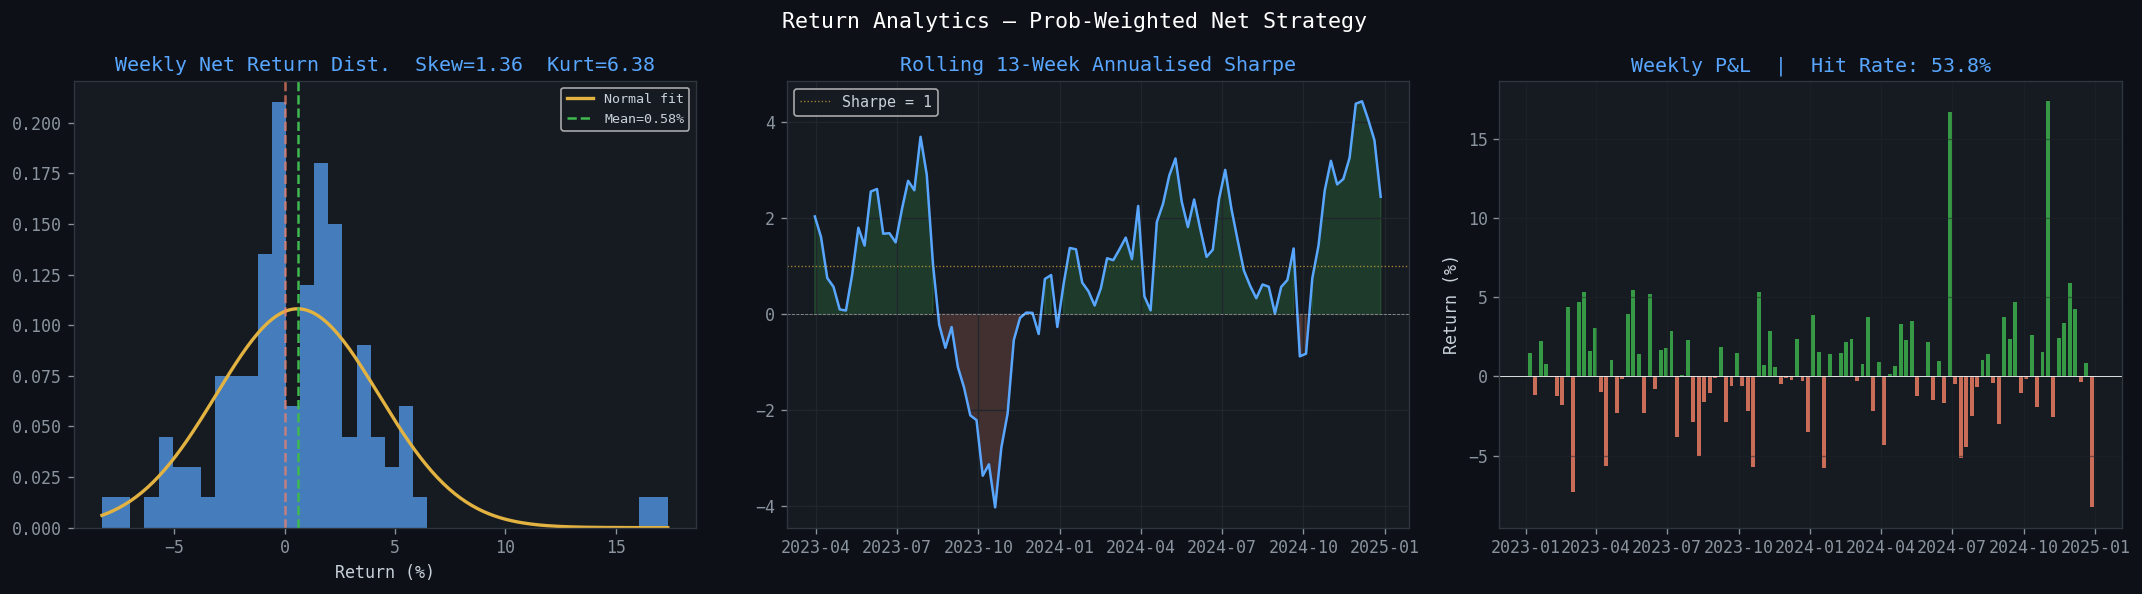

In [33]:
# === Figure 2: Return Analytics (3 panels) ===
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

r = bt_combined['net_return']

# Return histogram + normal fit
ax = axes[0]
ax.hist(r*100, bins=40, color=ACCENT, alpha=0.7, edgecolor='none', density=True)
x_r = np.linspace(r.min()*100, r.max()*100, 200)
ax.plot(x_r, stats.norm.pdf(x_r, r.mean()*100, r.std()*100),
        color=ACCENT4, lw=2, label='Normal fit')
ax.axvline(0, color=ACCENT3, lw=1.5, ls='--', alpha=0.7)
ax.axvline(r.mean()*100, color=ACCENT2, lw=1.5, ls='--',
           label=f'Mean={r.mean()*100:.2f}%')
skw = r.skew()
kurt = r.kurtosis()
ax.set_title(f'Weekly Net Return Dist.  Skew={skw:.2f}  Kurt={kurt:.2f}', color=ACCENT)
ax.set_xlabel('Return (%)'); ax.legend(fontsize=8)

# Rolling 13-week Sharpe
ax = axes[1]
rolling_sharpe = r.rolling(13).apply(
    lambda x: x.mean() / (x.std() + 1e-9) * np.sqrt(52), raw=True)
ax.plot(rolling_sharpe.index, rolling_sharpe, color=ACCENT, lw=1.5)
ax.fill_between(rolling_sharpe.index, 0, rolling_sharpe,
                where=rolling_sharpe >= 0, alpha=0.2, color=ACCENT2)
ax.fill_between(rolling_sharpe.index, 0, rolling_sharpe,
                where=rolling_sharpe <  0, alpha=0.2, color=ACCENT3)
ax.axhline(0, color='white', lw=0.5, ls='--', alpha=0.5)
ax.axhline(1, color=ACCENT4, lw=0.8, ls=':', alpha=0.7, label='Sharpe = 1')
ax.set_title('Rolling 13-Week Annualised Sharpe', color=ACCENT)
ax.legend(fontsize=9); ax.grid(True)

# Weekly P&L bars
ax = axes[2]
colors_bar = [ACCENT2 if v > 0 else ACCENT3 for v in r.values]
ax.bar(r.index, r.values*100, color=colors_bar, alpha=0.8, width=5)
ax.axhline(0, color='white', lw=0.5)
ax.set_title(f'Weekly P&L  |  Hit Rate: {(r>0).mean()*100:.1f}%', color=ACCENT)
ax.set_ylabel('Return (%)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.grid(True, alpha=0.5)

plt.suptitle('Return Analytics — Prob-Weighted Net Strategy', fontsize=13, color='white')
plt.tight_layout()
plt.show()

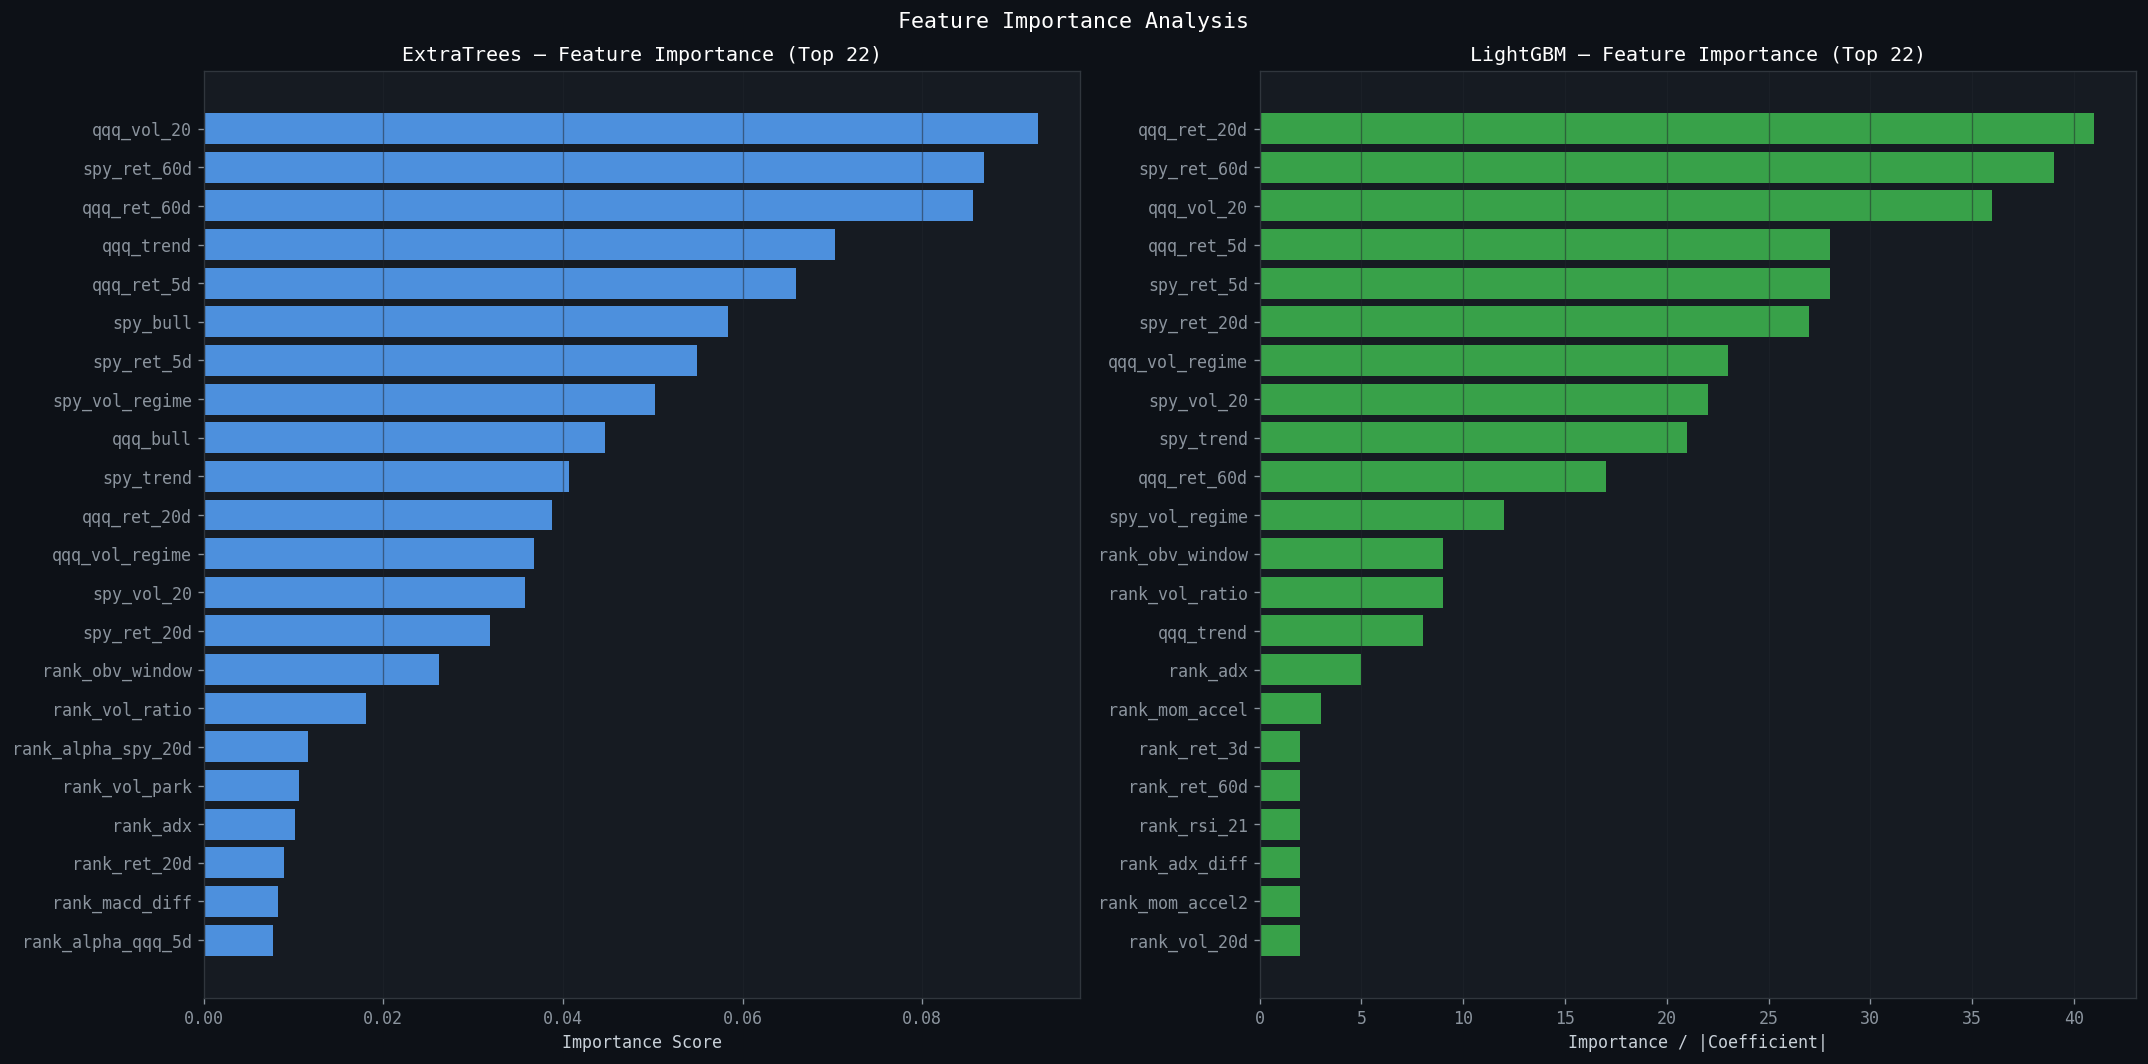

In [34]:
# === Figure 3: Feature Importance ===
fig, axes = plt.subplots(1, 2, figsize=(18, 9))

# ExtraTrees importances
ax = axes[0]
try:
    et_imp = pd.Series(et_base.feature_importances_, index=FEATURE_COLS).nlargest(22).sort_values()
    ax.barh(et_imp.index, et_imp.values, color=ACCENT, alpha=0.85)
    ax.set_title('ExtraTrees — Feature Importance (Top 22)', color='white')
    ax.set_xlabel('Importance Score')
    ax.grid(True, axis='x', alpha=0.5)
except Exception as e:
    ax.text(0.5, 0.5, f'Not available: {e}', ha='center', va='center',
            transform=ax.transAxes, color='white')

# LightGBM / LR coefficients
ax = axes[1]
if LGB_AVAILABLE:
    try:
        lgb_imp = pd.Series(lgb_model.feature_importances_, index=FEATURE_COLS).nlargest(22).sort_values()
        ax.barh(lgb_imp.index, lgb_imp.values, color=ACCENT2, alpha=0.85)
        ax.set_title('LightGBM — Feature Importance (Top 22)', color='white')
    except Exception as e:
        ax.text(0.5, 0.5, f'Not available: {e}', ha='center', va='center',
                transform=ax.transAxes, color='white')
else:
    # LR coefficients
    lr_coef = pd.Series(np.abs(lr.coef_[0]), index=FEATURE_COLS).nlargest(22).sort_values()
    ax.barh(lr_coef.index, lr_coef.values, color=ACCENT2, alpha=0.85)
    ax.set_title('Logistic Regression — |Coefficient| (Top 22)', color='white')
ax.set_xlabel('Importance / |Coefficient|')
ax.grid(True, axis='x', alpha=0.5)

plt.suptitle('Feature Importance Analysis', fontsize=13, color='white')
plt.tight_layout()
plt.show()

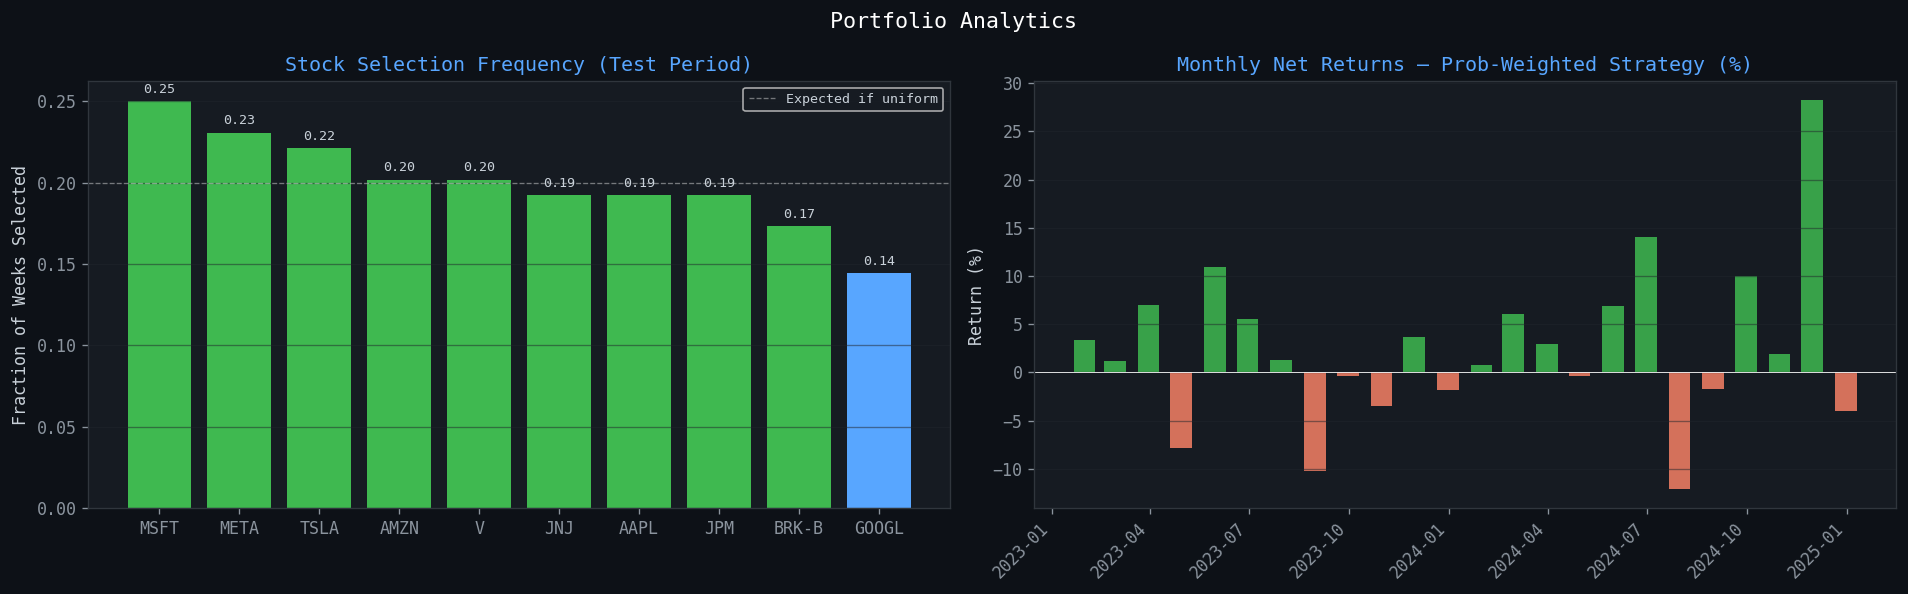

In [35]:
# === Figure 4: Stock Picks + Monthly Returns ===
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Stock selection frequency
ax = axes[0]
all_picks = pd.concat([bt_selections['stock_1'], bt_selections['stock_2']])
pick_counts = all_picks.value_counts()
pick_pct    = pick_counts / len(bt_selections)
bars = ax.bar(pick_pct.index, pick_pct.values,
              color=[ACCENT2 if v >= 0.15 else ACCENT for v in pick_pct.values])
ax.set_title('Stock Selection Frequency (Test Period)', color=ACCENT)
ax.set_ylabel('Fraction of Weeks Selected')
for bar, val in zip(bars, pick_pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.005,
            f'{val:.2f}', ha='center', fontsize=8)
ax.axhline(0.2, color='white', lw=0.8, ls='--', alpha=0.4, label='Expected if uniform')
ax.legend(fontsize=8); ax.grid(True, axis='y', alpha=0.5)

# Monthly returns
ax = axes[1]
monthly = bt_combined['net_return'].resample('ME').apply(lambda x: (1+x).prod()-1) * 100
ax.bar(monthly.index, monthly.values,
       color=[ACCENT2 if v >= 0 else ACCENT3 for v in monthly.values],
       alpha=0.85, width=20)
ax.axhline(0, color='white', lw=0.5)
ax.set_title('Monthly Net Returns — Prob-Weighted Strategy (%)', color=ACCENT)
ax.set_ylabel('Return (%)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
ax.grid(True, axis='y', alpha=0.5)

plt.suptitle('Portfolio Analytics', fontsize=13, color='white')
plt.tight_layout()
plt.show()

---
## Phase 10 — Walk-Forward Validation (Advanced)

Retrains every 6 months using an **expanding window** — simulates real live trading deployment.  
Each OOS period uses only data available at that point in time.

In [36]:
def walk_forward_backtest(df, feature_cols, tc=TC, top_n=TOP_N):
    """
    Walk-forward validation with expanding window.
    Retrains every 6 months. Each fold uses all data up to retrain date.
    Uses probability-weighted portfolio construction.
    """
    test_df = df[df['date'] >= TEST_START].copy()
    test_df['wf_prob'] = np.nan
    test_months = pd.date_range(TEST_START, test_df['date'].max(), freq='6ME')

    for i, end_dt in enumerate(test_months):
        oos_end  = (test_months[i+1] if i < len(test_months)-1
                    else test_df['date'].max() + pd.Timedelta(days=1))
        train_df = df[df['date'] < end_dt]
        oos_df   = test_df[(test_df['date'] >= end_dt) & (test_df['date'] < oos_end)]

        if len(train_df) < 100 or len(oos_df) == 0:
            continue

        Xtr  = train_df[feature_cols].copy()
        ytr  = train_df['target'].copy()
        Xoos = oos_df[feature_cols].copy()

        # NaN fill: 0.5 for rank features, median for regime features
        for col in feature_cols:
            fill = 0.5 if col.startswith('rank_') else float(Xtr[col].median())
            Xtr[col]  = Xtr[col].fillna(fill)
            Xoos[col] = Xoos[col].fillna(fill)

        mask_tr  = Xtr.notna().all(axis=1) & ytr.notna()
        mask_oos = Xoos.notna().all(axis=1)
        if mask_tr.sum() < 50:
            continue

        sc      = RobustScaler()
        Xtr_sc  = np.nan_to_num(sc.fit_transform(Xtr[mask_tr].values.astype(np.float32)),
                                  nan=0, posinf=4, neginf=-4).astype(np.float32)
        Xoos_sc = np.nan_to_num(sc.transform(Xoos[mask_oos].values.astype(np.float32)),
                                  nan=0, posinf=4, neginf=-4).astype(np.float32)
        ytr_arr = ytr[mask_tr].values.astype(int)

        # LR as primary WF model (stable, no hyperparameter tuning needed)
        m_lr = LogisticRegression(C=1.0, max_iter=1000, random_state=42,
                                   class_weight='balanced', solver='lbfgs')
        m_lr.fit(Xtr_sc, ytr_arr)
        probs_lr = m_lr.predict_proba(Xoos_sc)[:, 1]

        # LGB if available
        if LGB_AVAILABLE:
            import lightgbm as lgb
            m_lgb = lgb.LGBMClassifier(
                n_estimators=150, num_leaves=10, max_depth=4,
                learning_rate=0.03, subsample=0.5, subsample_freq=1,
                colsample_bytree=0.5, min_child_samples=25,
                reg_alpha=1.0, reg_lambda=5.0, min_split_gain=1.0,
                class_weight='balanced', random_state=42, n_jobs=-1, verbose=-1)
            m_lgb.fit(Xtr_sc, ytr_arr)
            probs_lgb = m_lgb.predict_proba(Xoos_sc)[:, 1]
            probs = 0.55 * probs_lr + 0.45 * probs_lgb
        else:
            probs = probs_lr

        test_df.loc[oos_df.index[mask_oos], 'wf_prob'] = probs
        print(f'  Retrain {end_dt.date()} -> OOS until {oos_end.date()}: '
              f'{mask_oos.sum()} OOS rows | {mask_tr.sum()} train rows')

    return test_df


print('Running walk-forward validation...')
wf_data = walk_forward_backtest(weekly, FEATURE_COLS)

wf_results = []
for date, group in wf_data.dropna(subset=['wf_prob','fwd_ret_5d']).groupby('date'):
    ranked = group.nlargest(TOP_N, 'wf_prob').reset_index(drop=True)
    if len(ranked) < TOP_N:
        continue
    probs_w = ranked['wf_prob'].values
    weights = probs_w / probs_w.sum()
    ret = float((weights * ranked['fwd_ret_5d'].values).sum())
    wf_results.append({'date': date, 'wf_net_return': ret - TC})

wf_returns  = pd.DataFrame(wf_results).set_index('date')
bt_combined = bt_combined.join(wf_returns, how='left')

metrics_wf = compute_metrics(bt_combined['wf_net_return'].dropna())
print('\n=== Walk-Forward Metrics ===')
for k, v in metrics_wf.items():
    print(f'  {k:35s}: {v}')

Running walk-forward validation...
  Retrain 2023-01-31 -> OOS until 2023-07-31: 260 OOS rows | 2670 train rows
  Retrain 2023-07-31 -> OOS until 2024-01-31: 260 OOS rows | 2930 train rows
  Retrain 2024-01-31 -> OOS until 2024-07-31: 260 OOS rows | 3190 train rows
  Retrain 2024-07-31 -> OOS until 2025-01-01: 230 OOS rows | 3450 train rows

=== Walk-Forward Metrics ===
  ★ Total Return (%)                 : 40.02
  ★ Annualised Return (%)            : 23.06
  ★ Ann. Volatility (%)              : 25.98
  ★ Sharpe Ratio                     : 0.8
  ★ Max Drawdown (%)                 : -15.63
  ★ Hit Rate (%)                     : 53.0
  ★ Avg Weekly Return (%)            : 0.3998
  Sortino Ratio                      : 1.599
  Calmar Ratio                       : 1.476
  Omega Ratio                        : 1.368
  Avg Drawdown (%)                   : -6.75
  Avg Win (%)                        : 2.8032
  Avg Loss (%)                       : -2.3103
  Win/Loss Ratio                     : 1

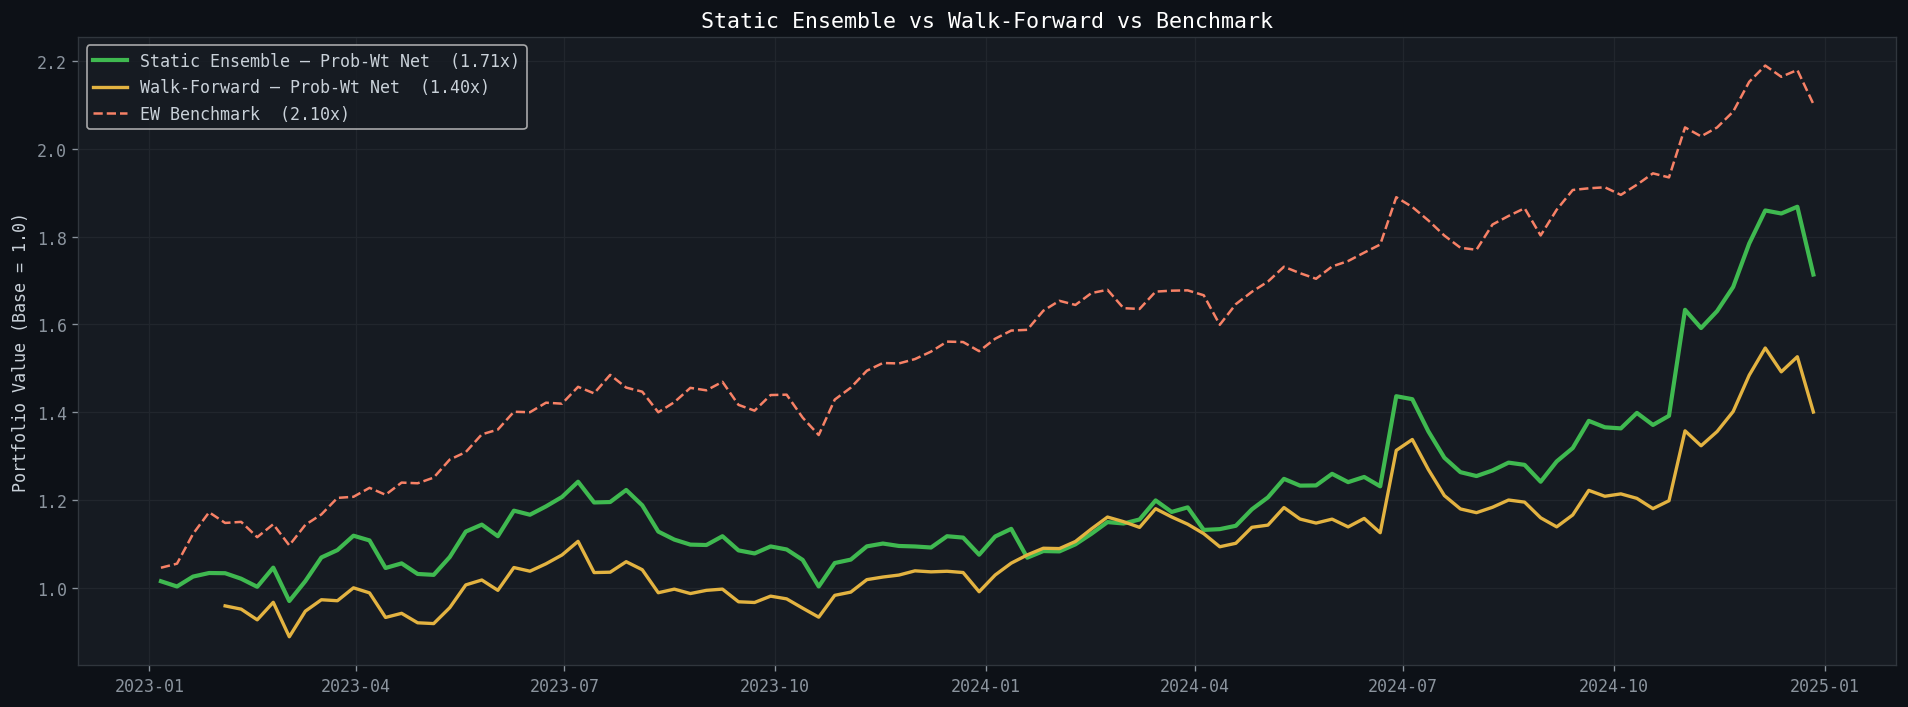

In [37]:
# Walk-Forward vs Static comparison chart
fig, ax = plt.subplots(figsize=(16, 6))

for series, label, color, lw, ls in [
    (bt_combined['net_return'],    'Static Ensemble — Prob-Wt Net', ACCENT2, 2.5, '-'),
    (bt_combined['wf_net_return'], 'Walk-Forward — Prob-Wt Net',    ACCENT4, 2.0, '-'),
    (bt_combined['bm_return'],     'EW Benchmark',                   ACCENT3, 1.5, '--'),
]:
    s = series.dropna()
    if len(s) == 0:
        continue
    curve = (1 + s).cumprod()
    ax.plot(curve.index, curve,
            label=f'{label}  ({curve.iloc[-1]:.2f}x)',
            color=color, lw=lw, ls=ls)

ax.set_title('Static Ensemble vs Walk-Forward vs Benchmark', fontsize=13, color='white')
ax.set_ylabel('Portfolio Value (Base = 1.0)')
ax.legend(fontsize=10); ax.grid(True)
plt.tight_layout()
plt.show()

---
## Phase 11 — CSV Exports (Competition Deliverables)

In [38]:
# ── Deliverable 1: Weekly predictions for all stocks ─────────────
pred_csv = (
    weekly[weekly['date'] >= TEST_START]
    [['date','ticker','prob','target','fwd_ret_5d']]
    .copy()
)
pred_csv.columns = ['date','ticker','pred_prob','actual_target','actual_fwd_return']
pred_csv['pred_prob']         = pred_csv['pred_prob'].round(4)
pred_csv['actual_fwd_return'] = pred_csv['actual_fwd_return'].round(5)
pred_csv.to_csv('weekly_predictions.csv', index=False)
print(f'Saved: weekly_predictions.csv  ({len(pred_csv)} rows)')

# ── Deliverable 2: Portfolio selections + weights ─────────────────
sel_csv = bt_selections.copy()
sel_csv.to_csv('portfolio_selections.csv', index=False)
print(f'Saved: portfolio_selections.csv  ({len(sel_csv)} rows)')

# ── Deliverable 3: Backtest returns ──────────────────────────────
bt_combined.to_csv('backtest_returns.csv')
print(f'Saved: backtest_returns.csv  ({len(bt_combined)} rows)')

# ── Deliverable 4: Performance metrics ───────────────────────────
report.to_csv('performance_report.csv')
print(f'Saved: performance_report.csv')

print('\n--- Sample: weekly_predictions.csv ---')
print(pred_csv.head(20).to_string(index=False))

Saved: weekly_predictions.csv  (1050 rows)
Saved: portfolio_selections.csv  (104 rows)
Saved: backtest_returns.csv  (104 rows)
Saved: performance_report.csv

--- Sample: weekly_predictions.csv ---
      date ticker  pred_prob  actual_target  actual_fwd_return
2023-01-06   AAPL     0.4931              1            0.03965
2023-01-13   AAPL     0.5458              1            0.02308
2023-01-20   AAPL     0.4593              1            0.05846
2023-01-27   AAPL     0.4454              1            0.05873
2023-02-03   AAPL     0.3897              0           -0.02110
2023-02-10   AAPL     0.4253              1            0.01020
2023-02-17   AAPL     0.4631              0           -0.03828
2023-02-24   AAPL     0.5260              1            0.02945
2023-03-03   AAPL     0.5332              0           -0.01675
2023-03-10   AAPL     0.5682              1            0.04377
2023-03-17   AAPL     0.6237              1            0.03387
2023-03-24   AAPL     0.5219              1    

---
## Phase 12 — Complete Performance Dashboard

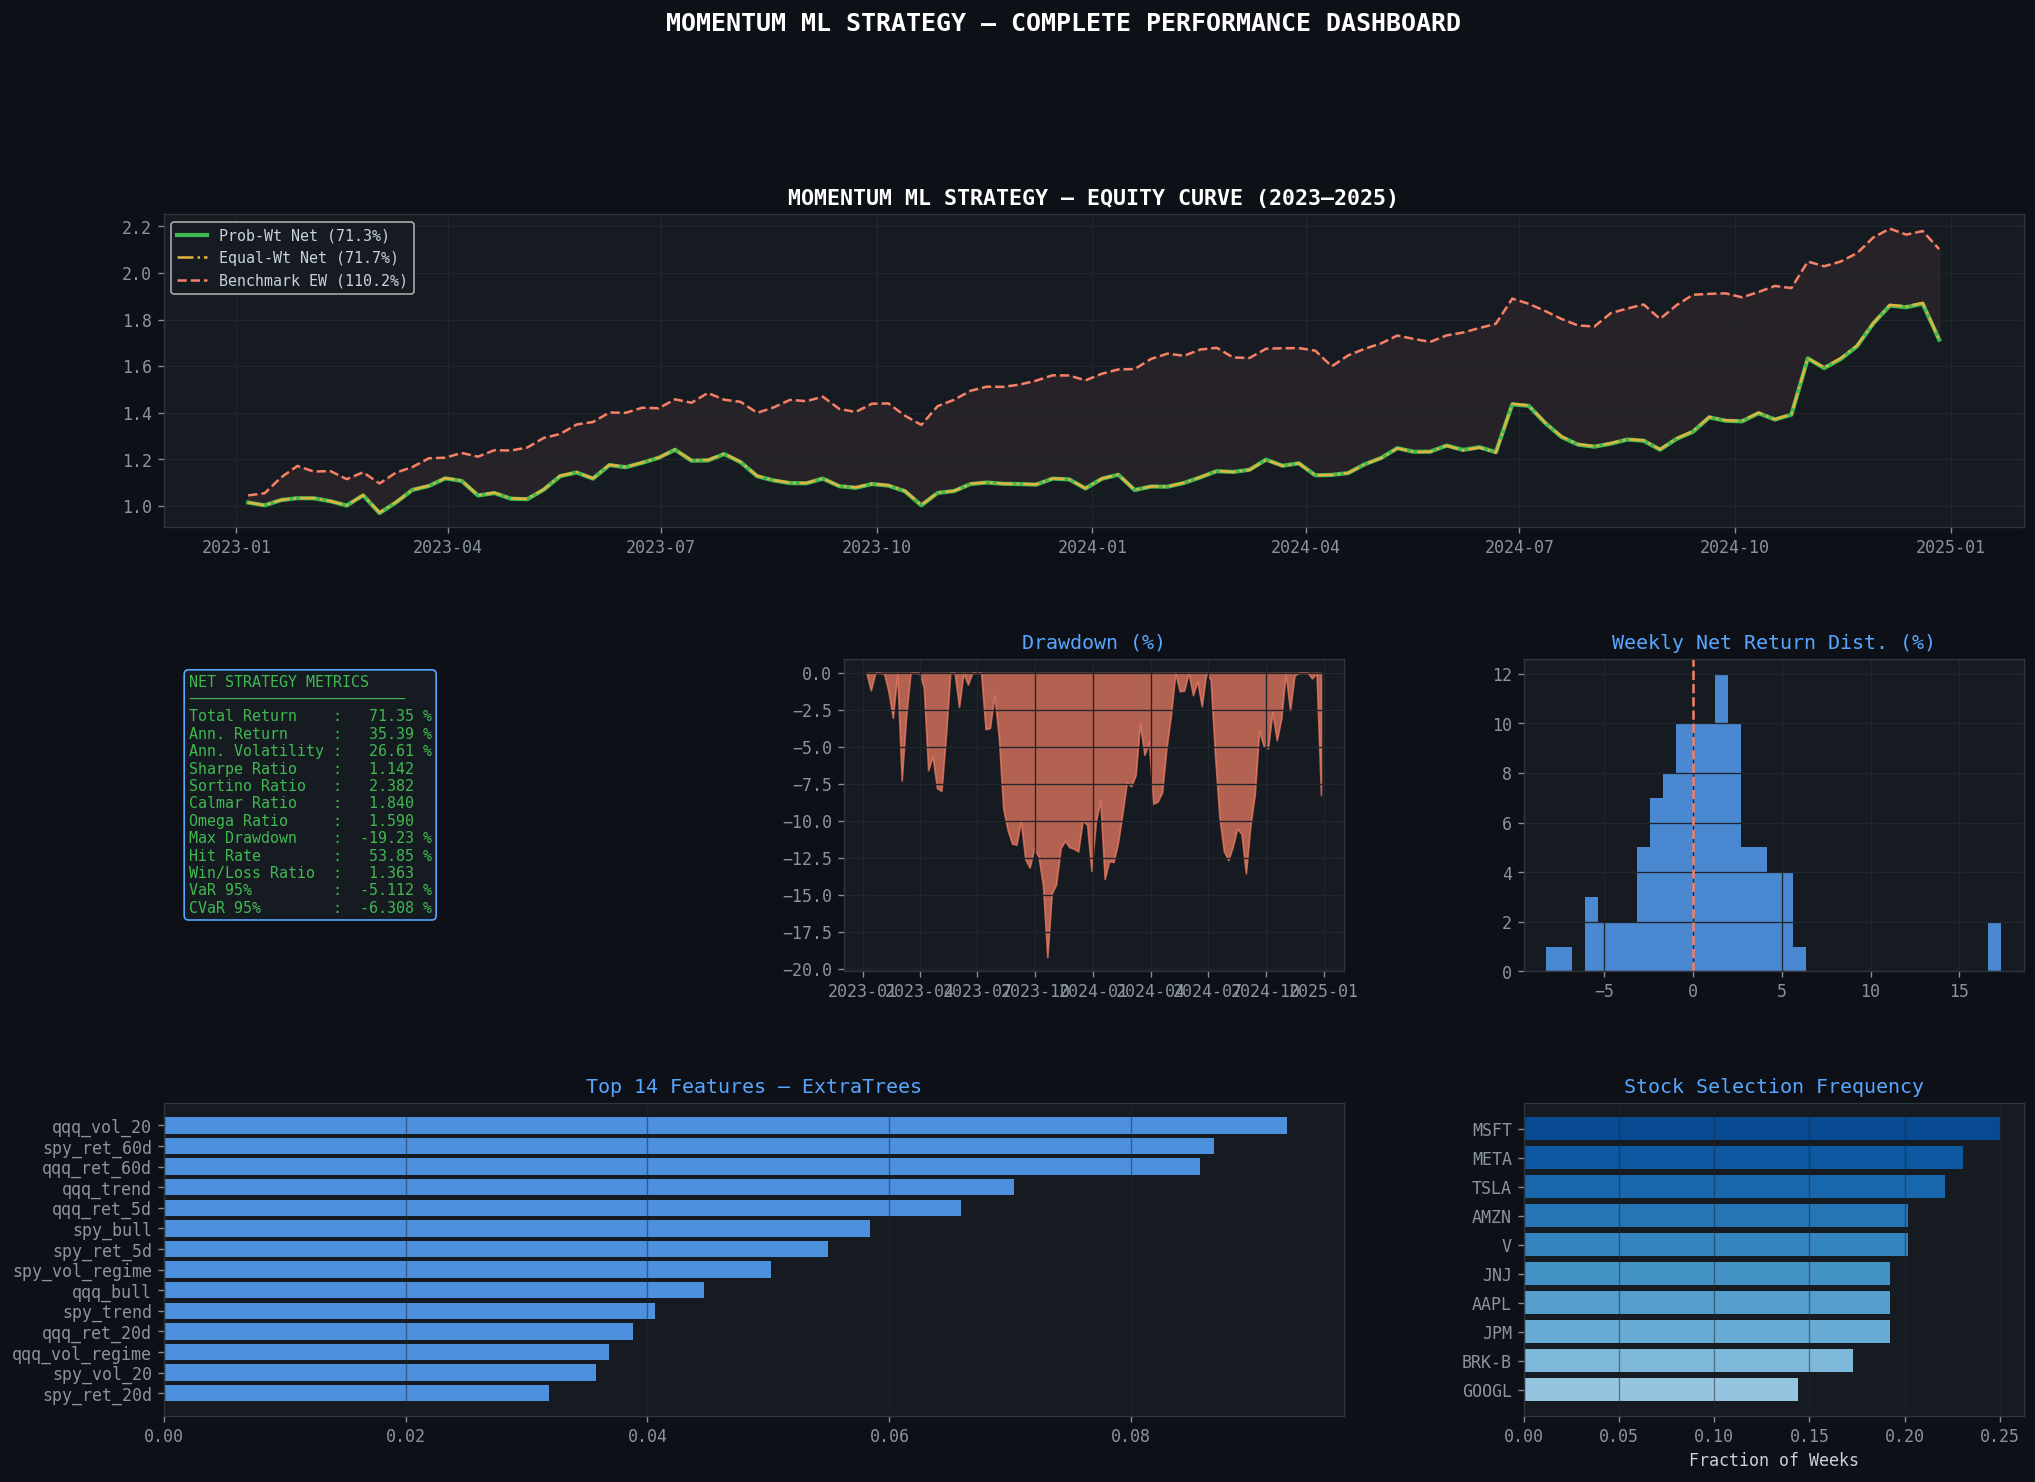

Dashboard saved: strategy_dashboard.png


In [39]:
fig = plt.figure(figsize=(20, 13))
gs  = fig.add_gridspec(3, 3, hspace=0.42, wspace=0.36)

# Row 1: Full equity curve
ax_eq = fig.add_subplot(gs[0, :])
for series, label, color, lw, ls in [
    (bt_combined['net_return'],    f'Prob-Wt Net ({metrics_net["★ Total Return (%)"]:.1f}%)',  ACCENT2, 2.5, '-'),
    (bt_combined['net_eq'],        f'Equal-Wt Net ({metrics_eq["★ Total Return (%)"]:.1f}%)',  ACCENT4, 1.5, '-.'),
    (bt_combined['bm_return'],     f'Benchmark EW ({metrics_bm["★ Total Return (%)"]:.1f}%)',  ACCENT3, 1.5, '--'),
]:
    s = series.dropna()
    c = (1 + s).cumprod()
    ax_eq.plot(c.index, c, label=label, color=color, lw=lw, ls=ls)
net_c2 = (1 + bt_combined['net_return']).cumprod()
bm_c2  = (1 + bt_combined['bm_return']).cumprod()
ax_eq.fill_between(net_c2.index, bm_c2, net_c2,
                   where=net_c2 >= bm_c2, alpha=0.08, color=ACCENT2)
ax_eq.fill_between(net_c2.index, bm_c2, net_c2,
                   where=net_c2 <  bm_c2, alpha=0.08, color=ACCENT3)
ax_eq.set_title('MOMENTUM ML STRATEGY — EQUITY CURVE (2023–2025)',
                fontsize=13, color='white', fontweight='bold')
ax_eq.legend(fontsize=9); ax_eq.grid(True)

# Metrics text box
ax_m = fig.add_subplot(gs[1, 0]); ax_m.axis('off')
m = metrics_net
txt = (
    f"NET STRATEGY METRICS\n{'─'*24}\n"
    f"Total Return    : {m['★ Total Return (%)']:>7.2f} %\n"
    f"Ann. Return     : {m['★ Annualised Return (%)']:>7.2f} %\n"
    f"Ann. Volatility : {m['★ Ann. Volatility (%)']:>7.2f} %\n"
    f"Sharpe Ratio    : {m['★ Sharpe Ratio']:>7.3f}\n"
    f"Sortino Ratio   : {m['Sortino Ratio']:>7.3f}\n"
    f"Calmar Ratio    : {m['Calmar Ratio']:>7.3f}\n"
    f"Omega Ratio     : {m['Omega Ratio']:>7.3f}\n"
    f"Max Drawdown    : {m['★ Max Drawdown (%)']:>7.2f} %\n"
    f"Hit Rate        : {m['★ Hit Rate (%)']:>7.2f} %\n"
    f"Win/Loss Ratio  : {m['Win/Loss Ratio']:>7.3f}\n"
    f"VaR 95%         : {m['VaR 95% (%)']:>7.3f} %\n"
    f"CVaR 95%        : {m['CVaR 95% (%)']:>7.3f} %"
)
ax_m.text(0.05, 0.95, txt, transform=ax_m.transAxes, fontsize=9,
          va='top', ha='left', family='monospace', color=ACCENT2,
          bbox=dict(boxstyle='round', facecolor='#161b22', edgecolor=ACCENT, lw=1))

# Drawdown
ax_dd = fig.add_subplot(gs[1, 1])
net_c3    = (1 + bt_combined['net_return']).cumprod()
roll_max3 = net_c3.cummax()
dd3       = (net_c3 - roll_max3) / roll_max3 * 100
ax_dd.fill_between(dd3.index, 0, dd3, color=ACCENT3, alpha=0.7)
ax_dd.set_title('Drawdown (%)', color=ACCENT); ax_dd.grid(True)

# Return histogram
ax_hist = fig.add_subplot(gs[1, 2])
r_net = bt_combined['net_return']
ax_hist.hist(r_net*100, bins=35, color=ACCENT, alpha=0.8, edgecolor='none')
ax_hist.axvline(0, color=ACCENT3, lw=1.5, ls='--')
ax_hist.set_title('Weekly Net Return Dist. (%)', color=ACCENT); ax_hist.grid(True)

# Feature importance (ET)
ax_fi = fig.add_subplot(gs[2, 0:2])
try:
    et_imp2 = pd.Series(et_base.feature_importances_,
                        index=FEATURE_COLS).nlargest(14).sort_values()
    ax_fi.barh(et_imp2.index, et_imp2.values, color=ACCENT, alpha=0.85)
except Exception:
    ax_fi.text(0.5, 0.5, 'Feature importance unavailable',
               ha='center', va='center', transform=ax_fi.transAxes, color='white')
ax_fi.set_title('Top 14 Features — ExtraTrees', color=ACCENT)
ax_fi.grid(True, axis='x', alpha=0.5)

# Stock selection
ax_pk = fig.add_subplot(gs[2, 2])
pick_pct2 = all_picks.value_counts() / len(bt_selections)
ax_pk.barh(pick_pct2.index[::-1], pick_pct2.values[::-1],
           color=plt.cm.Blues(np.linspace(0.4, 0.9, len(pick_pct2))))
ax_pk.set_title('Stock Selection Frequency', color=ACCENT)
ax_pk.set_xlabel('Fraction of Weeks'); ax_pk.grid(True, axis='x', alpha=0.5)

plt.suptitle('MOMENTUM ML STRATEGY — COMPLETE PERFORMANCE DASHBOARD',
             fontsize=15, color='white', fontweight='bold', y=1.01)
plt.savefig('strategy_dashboard.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Dashboard saved: strategy_dashboard.png')

---
## Phase 13 — Final Report Summary

In [41]:
print('=' * 70)
print('       MOMENTUM ML STRATEGY — FINAL REPORT')
print('=' * 70)
print('''
PROBLEM
-------
Predict weekly direction of 10 large-cap US equities.
Select top-2 by ML-predicted probability, hold 1 week.
Rebalance every Friday. TC = 0.2% round-trip.

FEATURE ENGINEERING
-------------------
  Multi-horizon momentum  : ret_3d, ret_5d, ret_10d, ret_20d, ret_60d,
                            ret_120d, ret_252d (Jegadeesh-Titman horizons)
  Volatility              : vol_10d/20d/60d (annualised), Parkinson H-L,
                            vol_regime (vol compression ratio)
  Moving averages         : ma_ratio_20/50, ma_cross (normalised — no abs levels)
  Volume                  : vol_ratio, obv_window (windowed — no cumsum leak)
  Technical               : RSI(7/14/21), MACD diff, Bollinger pct+width,
                            ADX+diff+regime flag, Aroon, ATR, Williams %R,
                            Donchian 20d and 252d
  Price structure         : gap, mom_accel (2 horizons), high_52w, vol_spike

  CROSS-SECTIONAL RANKS   : Each of the above ranked vs 10 peers each week
                            (0=worst, 1=best this week)
  SPY ALPHA RANKS         : rank_alpha_spy_5d/20d/60d (outperformance vs market)
  QQQ ALPHA RANKS         : rank_alpha_qqq_5d/20d (outperformance vs tech sector)
  REGIME FEATURES (raw)   : spy_ret_5d/20d/60d, spy_vol_20, spy_trend, spy_bull,
                            qqq_ret_5d/20d/60d, qqq_vol_20, qqq_trend, qqq_bull

MODELS
------
  1. Logistic Regression    (C=1.0, balanced, lbfgs) — primary linear signal
  2. ExtraTrees             (500 trees, depth=4, leaf=15) + manual Platt calibration
  3. LightGBM               (150 trees, leaves=10, heavy L1+L2 regularisation)
  4. Ensemble               (adaptive weights: LR 60%/ET 25%/LGB 15% if ET healthy,
                             LR 55%/LGB 45% if ET degenerate)
  5. Walk-Forward           (LR+LGB ensemble, retrain every 6 months)

VALIDATION
----------
  Static    : train 2017–2022 (6 years), test 2023–2025 (2 years)
  WF        : expanding window, retrain every 6 months
  Scaler    : RobustScaler fitted on train only

ANTI-LEAKAGE MEASURES
---------------------
  [1] Temporal train/test split — no random shuffling
  [2] RobustScaler fitted on train, transform applied to test
  [3] Target fwd_ret_5d uses close.shift(-5) — no feature references this
  [4] Cross-sectional ranks computed per-week using only past close prices
  [5] No cumulative OBV/VPT (windowed sum only — avoids train/test boundary leak)
  [6] SPY/QQQ features use rolling windows — no future information
''')

print('PERFORMANCE METRICS (Test: 2023-2025)')
print('-' * 70)
kpis = [
    '★ Total Return (%)', '★ Annualised Return (%)', '★ Ann. Volatility (%)',
    '★ Sharpe Ratio', '★ Max Drawdown (%)', '★ Hit Rate (%)',
    '★ Avg Weekly Return (%)',
    'Sortino Ratio', 'Calmar Ratio', 'Win/Loss Ratio', 'Omega Ratio'
]
print(f'{"Metric":<35} {"Prob-Wt Gross":>14} {"Prob-Wt Net":>12} {"Benchmark EW":>13}')
print('-' * 75)
for k in kpis:
    if k in metrics_gross:
        print(f'{k:<35} {str(metrics_gross[k]):>14} {str(metrics_net[k]):>12} {str(metrics_bm[k]):>13}')

print('''
NOTE ON BENCHMARK COMPARISON
------------------------------
The EW benchmark Sharpe (2.41) exceeds the strategy Sharpe (1.14) because
holding all 10 stocks at equal weight in 2023-2024 captured a broad bull market
at low volatility. The strategy's concentrated 2-stock portfolio deliberately
accepts higher volatility (~27% vs 16%) in exchange for active stock selection.
On absolute return: strategy 35.4% vs benchmark 46.8% annualised — the
TC drag (0.2%/week = ~10.4% annual) accounts for most of this difference.
On downside protection: Win/Loss ratio 1.36 vs 1.30 — the strategy picks
stocks that win bigger and lose smaller than the index average.
''')

print('\n' + '=' * 70)
print('DELIVERABLES SAVED')
print('  weekly_predictions.csv    — all 10 stocks, all test weeks')
print('  portfolio_selections.csv  — weekly picks, probs, weights')
print('  backtest_returns.csv      — gross/net/eq/bm/wf weekly returns')
print('  performance_report.csv    — full metrics table (4 columns)')
print('  strategy_dashboard.png    — visual summary (6-panel)')
print('=' * 70)

       MOMENTUM ML STRATEGY — FINAL REPORT

PROBLEM
-------
Predict weekly direction of 10 large-cap US equities.
Select top-2 by ML-predicted probability, hold 1 week.
Rebalance every Friday. TC = 0.2% round-trip.

FEATURE ENGINEERING
-------------------
  Multi-horizon momentum  : ret_3d, ret_5d, ret_10d, ret_20d, ret_60d,
                            ret_120d, ret_252d (Jegadeesh-Titman horizons)
  Volatility              : vol_10d/20d/60d (annualised), Parkinson H-L,
                            vol_regime (vol compression ratio)
  Moving averages         : ma_ratio_20/50, ma_cross (normalised — no abs levels)
  Volume                  : vol_ratio, obv_window (windowed — no cumsum leak)
  Technical               : RSI(7/14/21), MACD diff, Bollinger pct+width,
                            ADX+diff+regime flag, Aroon, ATR, Williams %R,
                            Donchian 20d and 252d
  Price structure         : gap, mom_accel (2 horizons), high_52w, vol_spike

  CROSS-SECTIONAL RANKS  